# Clasificación de planos anatómicos fetales
### Benchmark de EfficientNetV2-B0, DenseNet-121 y ViT-B/16, con explicabilidad (versión 4: versión 3 con el análisis estadístico de la sección 10 bis y las secciones 10 ter y 13 nuevas)

Dataset: FETAL_PLANES_DB (6 clases). El split train/test se rehace **por paciente** (ningún paciente aparece en los dos conjuntos) y los tres modelos se entrenan con el mismo pipeline y se evalúan sobre el mismo test.

Para ejecutarlo: activar GPU, correr las secciones 1 a 4 y luego cada modelo. Cada sección de modelo carga el archivo guardado en Drive si existe y, si no, lo entrena y lo guarda (se puede forzar con `RETRAIN_*`). La primera vez entrena los tres modelos; después solo los carga. Las figuras quedan en `dataset/figuras_v3`.

**Cambios respecto a la versión 2**
- El ViT ya no usa volteo vertical: ahora aplica los mismos aumentos que las CNNs (solo volteo horizontal, rotación y zoom).
- La precisión mixta (`mixed_float16`) ahora sí se activa en las CNNs; en la versión 2 solo estaba importada.
- Los casos de explicabilidad son aciertos con confianza alta y un error, para que las figuras sean representativas (sección 10g mide la confianza de cada modelo).
- Nueva sección 12: clasificación de los subplanos del cerebro (trans-thalamic, trans-cerebellum, trans-ventricular).
- Los modelos y resultados se guardan con sufijo `_v3`, así que no se pisan los de la versión 2 ni la primera versión. El archivo `split_pacientes.csv` se reutiliza, de modo que el test es el mismo que en la versión 2.
- Las imágenes aumentadas ahora viven en `dataset/Images_augmented` (separadas de las originales en `dataset/Images`); si quedaban `aug_*` mezcladas en `Images`, la sección 3 las mueve sola. La validación y el test solo tienen imágenes originales.
- Los modelos se buscan y se guardan en la carpeta `MODELS_DIR` (por defecto la carpeta del proyecto, donde el colab de data augmentation guarda los suyos); la sección 2 detecta la carpeta y lista los modelos que encuentra.
- **Nuevo en la versión 4:** sección 10 ter (Integrated Gradients también en el ViT, borrado e inserción para el ViT y medición de cuánta masa de los mapas cae en bordes y esquinas) y sección 13 (rendimiento por equipo y operador, validación cruzada por paciente con los tres modelos y un equipo fuera del entrenamiento). Las celdas de entrenamiento de la sección 13 están apagadas por defecto (`RUN_CV`, `RUN_LOMO`).


## 1. Configuración

In [ ]:
# 1. imports y configuración
import os, re, sys, json, math, random, time, subprocess, shutil
from pathlib import Path
os.environ['HF_HUB_DISABLE_PROGRESS_BARS'] = '1'

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

# torch y transformers se importan antes que tensorflow, si no chocan las librerías
import importlib.util
if importlib.util.find_spec('transformers') is None:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'transformers'], check=True)
import torch, torch._dynamo
import transformers
transformers.logging.set_verbosity_error()

import tensorflow as tf
for g in tf.config.list_physical_devices('GPU'):
    tf.config.experimental.set_memory_growth(g, True)    # deja memoria libre para pytorch

from tensorflow.keras import Input, Model, mixed_precision
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.applications import EfficientNetV2B0, DenseNet121
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.utils import class_weight

SEED = 42
USE_MIXED_PRECISION = True      # acelera las CNNs y ahorra memoria; el softmax final sigue en float32
if USE_MIXED_PRECISION:
    mixed_precision.set_global_policy('mixed_float16')
print('precisión mixta:', mixed_precision.global_policy().name)
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

IMG_SIZE   = 224
BATCH_SIZE = 64
WEIGHTS    = 'imagenet'

# mismos colores para cada modelo en todas las figuras
COLORES = {'EfficientNetV2-B0': '#4C72B0', 'DenseNet-121': '#55A868', 'ViT-B/16': '#8172B2'}
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

precisión mixta: mixed_float16


## 2. Drive y rutas

In [ ]:
# 2. montar drive y buscar el dataset
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass

CANDIDATAS = [
    Path('/content/drive/MyDrive/Proyecto/dataset'),
    Path('/content/drive/MyDrive/IA2/proyecto_IA2/dataset'),
    Path('/content/drive/MyDrive/dataset'),
]
DATASET_DIR = next((p for p in CANDIDATAS if (p / 'fetal_planes_train.csv').exists()), None)
if DATASET_DIR is None:
    hallados = list(Path('/content/drive/MyDrive').glob('*/dataset/fetal_planes_train.csv')) + \
               list(Path('/content/drive/MyDrive').glob('*/*/dataset/fetal_planes_train.csv'))
    DATASET_DIR = hallados[0].parent if hallados else None
if DATASET_DIR is None:
    raise FileNotFoundError('No se encontró fetal_planes_train.csv, agregar la ruta a CANDIDATAS')

if '.shortcut-targets-by-id' in str(DATASET_DIR.resolve()):
    print('Ojo: se está usando la carpeta compartida, mejor trabajar con una copia propia')

CSV_PATH_train = DATASET_DIR / 'fetal_planes_train.csv'
CSV_PATH_test  = DATASET_DIR / 'fetal_planes_test.csv'
image_dir      = DATASET_DIR / 'Images'
FIGS_DIR       = DATASET_DIR / 'figuras_v3'; FIGS_DIR.mkdir(exist_ok=True)

# Imágenes aumentadas: carpeta APARTE de las originales (misma configuración del colab de data augmentation)
AUG_DIR        = DATASET_DIR / 'Images_augmented'; AUG_DIR.mkdir(exist_ok=True)

# Carpeta de los modelos: la primera de esta lista que ya contenga modelos (.keras / .pt).
# El colab de data augmentation los guarda en la carpeta del proyecto (la que contiene a 'dataset').
_CAND_MODELOS = [DATASET_DIR.parent, DATASET_DIR / 'modelos', DATASET_DIR.parent / 'modelos', DATASET_DIR]
MODELS_DIR = next((d for d in _CAND_MODELOS if d.exists() and (any(d.glob('*.keras')) or any(d.glob('*.pt')))),
                  DATASET_DIR.parent)
print('Imágenes aumentadas:', AUG_DIR)
print('Carpeta de modelos :', MODELS_DIR, '->', sorted(p.name for p in list(MODELS_DIR.glob('*.keras')) + list(MODELS_DIR.glob('*.pt'))))
META_PATH      = DATASET_DIR / 'benchmark_meta_v3.json'
SPLIT_PATH     = DATASET_DIR / 'split_pacientes.csv'
print('Dataset:', DATASET_DIR)

def find_file(name):
    for d in [MODELS_DIR, DATASET_DIR, DATASET_DIR / 'modelos', DATASET_DIR.parent / 'modelos', DATASET_DIR.parent]:
        if (d / name).exists():
            return d / name
    return None

def load_meta():
    return json.loads(META_PATH.read_text()) if META_PATH.exists() else {}

def save_meta(meta):
    META_PATH.write_text(json.dumps(meta, indent=1))

Mounted at /content/drive
Imágenes aumentadas: /content/drive/MyDrive/IA2/proyecto_IA2/dataset/Images_augmented
Carpeta de modelos : /content/drive/MyDrive/IA2/proyecto_IA2/modelos -> ['EfficientNetV2B0_PlanosFetales.keras', 'EfficientNetV2B0_PlanosFetales_sinDA.keras', 'EfficientNetV2B0_subplanos_v3.keras', 'EfficientNetV2B0_v3.keras', 'EfficientNetV2B0_v3_DA.keras', 'ViT_v3.pt']
Dataset: /content/drive/MyDrive/IA2/proyecto_IA2/dataset


## 3. Datos y split por paciente

Originales en Images: 12412 | aumentadas en Images_augmented: 4025
Pacientes: 1428 en train y 363 en test, 0 en comón
Aviso: USAR_AUG_DISCO es False, se entrenará SOLO con imágenes originales.

Train: 8552 (8552 originales + 0 aumentadas)
Entrenamiento 6876 | validación 1676 | test 2291


,train (originales),test
Plane,,
Fetal abdomen,6.4,6.6
Fetal brain,27.5,27.5
Fetal femur,9.5,8.5
Fetal thorax,15.4,14.8
Maternal cervix,13.6,11.7
Other,27.7,30.9


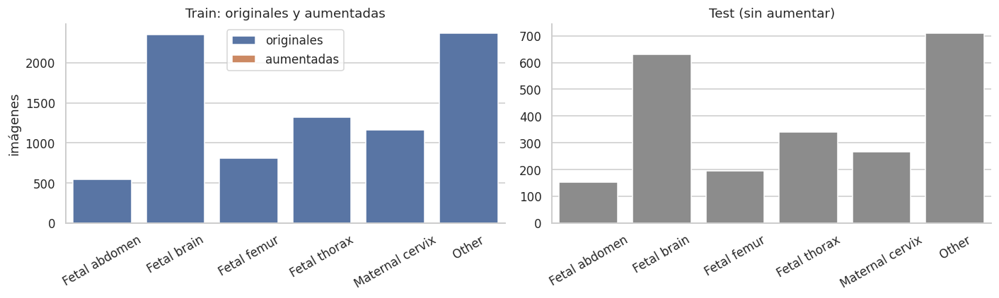

In [ ]:
# 3. datos: split por paciente, aumentadas y verificación
USAR_AUG_DISCO = False          # interruptor para usar o no las aumentadas
GENERAR_AUG_SI_FALTAN = True    # solo genera imágenes si no existe ninguna aug_* en Images_augmented
MAX_AUG_PER_CLASS = 1000

def patient_of(p):
    m = re.search(r'(Patient\d+)', Path(str(p)).name)
    return m.group(1) if m else Path(str(p)).name

# Si quedaron aumentadas mezcladas en Images (configuración anterior), se mueven a la carpeta aparte
MIGRAR_AUG_ANTIGUAS = True
if MIGRAR_AUG_ANTIGUAS:
    viejas = [p for p in image_dir.glob('aug_*')]
    for p in tqdm(viejas, desc='moviendo aug_ a Images_augmented', disable=len(viejas) == 0):
        destino_aug = AUG_DIR / p.name
        if destino_aug.exists():
            p.unlink()
        else:
            shutil.move(str(p), str(destino_aug))
    if len(viejas) > 0:
        print(f'{len(viejas)} imágenes aumentadas movidas de Images a {AUG_DIR.name}')

existentes = {p.name for p in image_dir.iterdir() if not p.name.startswith('aug_')}   # solo originales
existentes_aug = {p.name for p in AUG_DIR.iterdir()}
print('Originales en Images:', len(existentes), '| aumentadas en Images_augmented:', len(existentes_aug))

def leer_originales(csv):
    # Intenta leer usando ';' y si se parsea todo en una sola columna con comas, re-lee con ','
    df = pd.read_csv(csv, sep=';')
    if len(df.columns) == 1 and ',' in df.columns[0]:
        df = pd.read_csv(csv, sep=',')
    df['fname'] = df['filepath'].map(lambda x: Path(str(x)).name)
    df = df[~df['fname'].str.startswith('aug_')].drop_duplicates('fname')
    return df[['fname', 'Plane']]

# se juntan las imágenes originales de los dos CSV y se separan de nuevo, esta vez por paciente
df_all = pd.concat([leer_originales(CSV_PATH_train), leer_originales(CSV_PATH_test)]).drop_duplicates('fname').reset_index(drop=True)
falt = ~df_all['fname'].isin(existentes)
if falt.any():
    print(f'{falt.sum()} imágenes no existen en Images, se descartan')
    df_all = df_all[~falt].reset_index(drop=True)
df_all['patient'] = df_all['fname'].map(patient_of)

if SPLIT_PATH.exists():                      # el split se guarda para que todos usen el mismo
    sp = pd.read_csv(SPLIT_PATH, sep=';')
    df_all = df_all.merge(sp[['fname', 'split']], on='fname', how='left')
    assert df_all['split'].notna().all(), 'split_pacientes.csv no coincide con las imágenes, borrarlo para rehacerlo'
else:
    sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
    _, te_idx = next(sgkf.split(df_all, df_all['Plane'], groups=df_all['patient']))
    df_all['split'] = 'train'
    df_all.loc[te_idx, 'split'] = 'test'
    df_all[['fname', 'Plane', 'patient', 'split']].to_csv(SPLIT_PATH, sep=';', index=False)

orig_tr = df_all[df_all['split'] == 'train'].reset_index(drop=True)
df_test = df_all[df_all['split'] == 'test'].reset_index(drop=True)
for d in (orig_tr, df_test):
    d['filepath'] = d['fname'].map(lambda n: image_dir / n)

# verificación: ningón paciente en los dos conjuntos
repetidos = set(orig_tr['patient']) & set(df_test['patient'])
assert len(repetidos) == 0, f'{len(repetidos)} pacientes repetidos entre train y test'
print(f'Pacientes: {orig_tr.patient.nunique()} en train y {df_test.patient.nunique()} en test, 0 en comón')

# aumentadas: solo se usan las que vienen de imágenes del train nuevo
plane_de = dict(zip(orig_tr['fname'], orig_tr['Plane']))
patron = re.compile(r'^aug_(.+?)_(\d+)_(Patient.*)$')
filas, descartadas = [], 0
if USAR_AUG_DISCO:
    for name in sorted(existentes_aug):
        if name.startswith('aug_'):
            m = patron.match(name)
            if m and m.group(3) in plane_de:
                filas.append({'filepath': AUG_DIR / name, 'Plane': plane_de[m.group(3)]})
            else:
                descartadas += 1
    df_aug = pd.DataFrame(filas, columns=['filepath', 'Plane'])
    print(f'Aumentadas usadas: {len(df_aug)} | descartadas (su imagen original quedó en test): {descartadas}')
else:
    df_aug = pd.DataFrame(columns=['filepath', 'Plane'])

def augment_image(image_path):
    # volteo horizontal, rotación de +-15 grados y cambio de brillo/contraste
    img = cv2.imread(str(image_path))
    if img is None:
        return None
    if random.random() > 0.5:
        img = cv2.flip(img, 1)
    h, w = img.shape[:2]
    M = cv2.getRotationMatrix2D((w/2, h/2), random.randint(-15, 15), 1.0)
    img = cv2.warpAffine(img, M, (w, h), borderMode=cv2.BORDER_REFLECT)
    return cv2.convertScaleAbs(img, alpha=random.uniform(0.8, 1.2), beta=random.randint(-10, 10))

if len(df_aug) == 0 and GENERAR_AUG_SI_FALTAN and USAR_AUG_DISCO:
    counts = orig_tr['Plane'].value_counts(); target = counts.max(); nuevos = []
    for cls, n in counts.items():
        if cls == counts.idxmax():
            continue
        cant = min(max(target - n, int(n * 0.10)), MAX_AUG_PER_CLASS)
        base_df = orig_tr[orig_tr['Plane'] == cls]
        for i in tqdm(range(cant), desc=cls):
            src = base_df.sample(n=1).iloc[0]['filepath']
            out = augment_image(src)
            if out is None:
                continue
            dst = AUG_DIR / f"aug_{cls.replace(' ', '_')}_{i}_{Path(src).name}"
            cv2.imwrite(str(dst), out)
            nuevos.append({'filepath': dst, 'Plane': cls})
    df_aug = pd.DataFrame(nuevos, columns=['filepath', 'Plane'])
    print('Imágenes generadas:', len(df_aug))

if USAR_AUG_DISCO:
    df_train = pd.concat([orig_tr[['filepath', 'Plane']].assign(is_aug=False),
                          df_aug.assign(is_aug=True)], ignore_index=True)
else:
    df_train = orig_tr[['filepath', 'Plane']].assign(is_aug=False).copy()
    print('Aviso: USAR_AUG_DISCO es False, se entrenará SOLO con imágenes originales.')

df_train['patient'] = df_train['filepath'].map(patient_of)

classes = sorted(df_train['Plane'].unique())
class_to_idx = {c: i for i, c in enumerate(classes)}
num_classes = len(classes)
assert set(df_test['Plane'].unique()) <= set(classes)

# validación separada por paciente y solo con imágenes originales
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
tr_idx, va_idx = next(sgkf.split(df_train, df_train['Plane'], groups=df_train['patient']))
tr_df = df_train.iloc[tr_idx].reset_index(drop=True)
va_df = df_train.iloc[va_idx]; va_df = va_df[~va_df['is_aug']].reset_index(drop=True)
true_labels = df_test['Plane'].map(class_to_idx).values
pac_test = df_test['patient']

print(f'\nTrain: {len(df_train)} ({int((~df_train.is_aug).sum())} originales + {int(df_train.is_aug.sum())} aumentadas)')
print(f'Entrenamiento {len(tr_df)} | validación {len(va_df)} | test {len(df_test)}')

prop = pd.DataFrame({'train (originales)': orig_tr['Plane'].value_counts(normalize=True),
                     'test': df_test['Plane'].value_counts(normalize=True)}).loc[classes]
display((prop * 100).round(1))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.countplot(data=df_train, x='Plane', order=classes, hue='is_aug', hue_order=[False, True],
              palette=['#4C72B0', '#DD8452'], ax=ax[0])
ax[0].set_title('Train: originales y aumentadas'); ax[0].set_xlabel(''); ax[0].set_ylabel('imágenes')
ax[0].legend(['originales', 'aumentadas']); ax[0].tick_params(axis='x', rotation=30)
sns.countplot(data=df_test, x='Plane', order=classes, color='#8c8c8c', ax=ax[1])
ax[1].set_title('Test (sin aumentar)'); ax[1].set_xlabel(''); ax[1].set_ylabel('')
ax[1].tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.savefig(FIGS_DIR / 'distribucion_clases.png', dpi=150); plt.show()


## 4. Pipeline de datos para las CNNs

In [ ]:
# 4. pipeline tf.data
AUTOTUNE = tf.data.AUTOTUNE
CACHE_IN_RAM = True

def load_image(path, label):
    img = tf.io.read_file(path)
    img = tf.io.decode_image(img, channels=3, expand_animations=False)
    img.set_shape([None, None, 3])
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    img = tf.cast(tf.clip_by_value(img, 0, 255), tf.uint8)
    return img, tf.one_hot(label, num_classes)

def make_ds(df, training):
    paths  = df['filepath'].astype(str).values
    labels = df['Plane'].map(class_to_idx).values.astype('int32')
    ds = tf.data.Dataset.from_tensor_slices((paths, labels)).map(load_image, num_parallel_calls=AUTOTUNE)
    if CACHE_IN_RAM:
        ds = ds.cache()
    if training:
        ds = ds.shuffle(2048, seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = make_ds(tr_df, True)
val_ds   = make_ds(va_df, False)
test_ds  = make_ds(df_test, False)     # sin barajar, el orden coincide con true_labels

# aumentos dentro del modelo (solo actúan al entrenar)
augment = tf.keras.Sequential([
    tf.keras.layers.RandomFlip('horizontal'),
    tf.keras.layers.RandomRotation(30 / 360),
    tf.keras.layers.RandomZoom(0.2),
], name='augment')

_cw = class_weight.compute_class_weight('balanced', classes=np.arange(num_classes),
                                        y=tr_df['Plane'].map(class_to_idx).values)
CLASS_WEIGHT = {i: float(w) for i, w in enumerate(_cw)}
print('Pesos de clase:', {classes[i]: round(w, 2) for i, w in CLASS_WEIGHT.items()})

Pesos de clase: {'Fetal abdomen': 2.59, 'Fetal brain': 0.61, 'Fetal femur': 1.75, 'Fetal thorax': 1.07, 'Maternal cervix': 1.25, 'Other': 0.6}


## 5. Funciones para entrenar, evaluar y graficar

In [ ]:
# 5. funciones comunes
RESULTS = {}     # aquí queda lo de cada modelo: probabilidades, predicciones, reporte y parámetros

def build_cnn(base_fn, name, preprocess=None, n_classes=None):
    base = base_fn(include_top=False, weights=WEIGHTS, input_shape=(IMG_SIZE, IMG_SIZE, 3))
    base.trainable = False
    inputs = Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = augment(inputs)
    if preprocess == 'imagenet_torch':
        # DenseNet espera la imagen en [0,1] normalizada con la media y desviación de ImageNet
        x = tf.keras.layers.Rescaling(1 / 255.0, name='pre_rescale')(x)
        x = tf.keras.layers.Normalization(mean=[0.485, 0.456, 0.406], variance=[0.229**2, 0.224**2, 0.225**2], name='pre_norm')(x)
    x = base(x, training=False)
    x = GlobalAveragePooling2D()(x)
    x = Dense(64, activation='relu')(x)
    x = Dropout(0.1)(x)
    outputs = Dense(n_classes or num_classes, activation='softmax', dtype='float32')(x)
    return Model(inputs, outputs, name=name), base

def _callbacks(patience, ckpt):
    return [
        tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=patience, restore_best_weights=True, verbose=1),
        tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.3, patience=1, min_lr=1e-7, verbose=1),
        tf.keras.callbacks.ModelCheckpoint(ckpt, monitor='val_loss', save_best_only=True, save_weights_only=True, verbose=0),
    ]

def get_or_train_cnn(tag, base_fn, filename, retrain, ep_head, ep_fine, lr_head=1e-3, lr_fine=1e-5, preprocess=None, data=None):
    # data = (dataset de entrenamiento, dataset de validación, pesos de clase, número de clases); por defecto, los de las 6 clases
    tr_ds, va_ds, cw, n_cls = data if data is not None else (train_ds, val_ds, CLASS_WEIGHT, num_classes)
    path, meta = find_file(filename), load_meta()
    if path is not None and not retrain:
        print(f'Cargando {tag} desde {path}')
        return tf.keras.models.load_model(path, compile=False), meta.get(tag, {})

    print(f'Entrenando {tag}')
    model, base = build_cnn(base_fn, tag, preprocess, n_cls)
    t0 = time.time()
    model.compile(optimizer=tf.keras.optimizers.Adam(lr_head), loss='categorical_crossentropy', metrics=['accuracy'])
    h1 = model.fit(tr_ds, validation_data=va_ds, epochs=ep_head, class_weight=cw,
                   callbacks=_callbacks(2, f'/content/{tag}_head.weights.h5'))
    base.trainable = True
    for layer in base.layers:
        if isinstance(layer, tf.keras.layers.BatchNormalization):
            layer.trainable = False
    model.compile(optimizer=tf.keras.optimizers.Adam(lr_fine), loss='categorical_crossentropy', metrics=['accuracy'])
    h2 = model.fit(tr_ds, validation_data=va_ds, epochs=ep_fine, class_weight=cw,
                   callbacks=_callbacks(3, f'/content/{tag}_fine.weights.h5'))
    secs = time.time() - t0
    print(f'Tiempo de entrenamiento {tag}: {secs/60:.1f} min')

    MODELS_DIR.mkdir(exist_ok=True)
    destino = MODELS_DIR / filename
    if destino.exists():
        shutil.copy(destino, str(destino) + '.bak')      # copia de seguridad del modelo anterior
    model.save(destino)
    meta[tag] = {'train_time_s': secs,
                 'loss': h1.history['loss'] + h2.history['loss'],
                 'val_loss': h1.history['val_loss'] + h2.history['val_loss'],
                 'phase1_epochs': len(h1.history['loss'])}
    save_meta(meta)
    return model, meta[tag]

def evaluate_model(probs, nombre, params):
    pred = probs.argmax(1)
    print(classification_report(true_labels, pred, target_names=classes, digits=3))
    rep = classification_report(true_labels, pred, target_names=classes, output_dict=True)
    RESULTS[nombre] = {'probs': probs, 'pred': pred, 'rep': rep, 'params': params}

def plot_cm(nombre, cmap, fname):
    cm = confusion_matrix(true_labels, RESULTS[nombre]['pred'])
    plt.figure(figsize=(8, 6.5))
    sns.heatmap(cm, annot=True, fmt='d', cmap=cmap, xticklabels=classes, yticklabels=classes, linewidths=.5, linecolor='white')
    plt.title(f'Matriz de confusión: {nombre}'); plt.ylabel('Clase real'); plt.xlabel('Predicción')
    plt.xticks(rotation=40, ha='right'); plt.yticks(rotation=0)
    plt.tight_layout(); plt.savefig(FIGS_DIR / fname, dpi=150); plt.show()

def plot_loss(info, nombre, fname):
    if not info or 'loss' not in info:
        print(f'No hay historial de entrenamiento guardado para {nombre}')
        return
    ep = np.arange(1, len(info['loss']) + 1)
    color = COLORES[nombre]
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.plot(ep, info['loss'], '-o', color=color, label='entrenamiento')
    ax.plot(ep, info['val_loss'], '-s', color=color, alpha=.55, label='validación')
    k = int(np.argmin(info['val_loss']))
    ax.scatter(ep[k], info['val_loss'][k], s=140, facecolors='none', edgecolors='black', zorder=5)
    ax.annotate(f"mejor val: {info['val_loss'][k]:.3f}", (ep[k], info['val_loss'][k]),
                textcoords='offset points', xytext=(10, 14), fontsize=9)
    if info.get('phase1_epochs'):
        ax.axvline(info['phase1_epochs'] + 0.5, color='gray', ls='--', lw=1)
        ax.text(info['phase1_epochs'] + 0.6, ax.get_ylim()[1] * 0.92, 'fine-tuning', color='gray', fontsize=9)
    ax.set_title(f'Pérdida por época: {nombre}'); ax.set_xlabel('época'); ax.set_ylabel('pérdida')
    ax.set_xticks(ep); ax.legend()
    plt.tight_layout(); plt.savefig(FIGS_DIR / fname, dpi=150); plt.show()

## 6. Funciones de explicabilidad (CNNs)

In [ ]:
# 6. Grad-CAM, Score-CAM e Integrated Gradients
def split_cnn(model):
    # conv_model: imagen -> mapas de la última capa convolucional; run_head: mapas -> predicción
    idx = next(k for k, l in enumerate(model.layers) if isinstance(l, tf.keras.Model) and l.name != 'augment')
    x = inp = Input(shape=model.input_shape[1:])
    for l in model.layers[1:idx + 1]:
        x = l(x)
    conv_model = tf.keras.Model(inp, x)
    head_layers = model.layers[idx + 1:]
    def run_head(x):
        for l in head_layers:
            x = l(x, training=False)
        return x
    return conv_model, run_head

def get_gradcam(img_batch, conv_model, run_head, pred_idx):
    with tf.GradientTape() as tape:
        conv_out = tf.cast(conv_model(img_batch, training=False), tf.float32)
        tape.watch(conv_out)
        score = run_head(conv_out)[:, pred_idx]
    grads = tape.gradient(score, conv_out)
    pooled = tf.reduce_mean(grads, axis=(0, 1, 2))
    hm = tf.squeeze(conv_out[0] @ pooled[..., tf.newaxis])
    hm = tf.maximum(hm, 0) / (tf.reduce_max(hm) + 1e-8)
    return hm.numpy().astype(np.float32)

def get_scorecam(img_batch, conv_model, model, pred_idx, max_n=32, bs=16):
    feats = conv_model(img_batch, training=False)[0].numpy().astype(np.float32)
    h, w, c = feats.shape
    chans = list(range(0, c, max(1, c // max_n)))[:max_n]
    maps = np.stack([cv2.resize(feats[:, :, i], (IMG_SIZE, IMG_SIZE)) for i in chans])
    mn, mx = maps.min((1, 2), keepdims=True), maps.max((1, 2), keepdims=True)
    norm = (maps - mn) / (mx - mn + 1e-8)
    img = img_batch.numpy()[0]
    scores = []
    for i in range(0, len(chans), bs):
        masked = img[None] * norm[i:i+bs, :, :, None]
        scores.append(model(masked, training=False).numpy()[:, pred_idx])
    scores = np.concatenate(scores)
    sm = np.maximum(sum(s * feats[:, :, ch] for s, ch in zip(scores, chans)), 0)
    return (sm / sm.max() if sm.max() > 0 else sm).astype(np.float32)

def get_integrated_gradients(model, img_batch, pred_idx, num_steps=30, bs=8):
    img = tf.cast(img_batch, tf.float32)
    alphas = tf.reshape(tf.linspace(0.0, 1.0, num_steps + 1), (-1, 1, 1, 1))
    interp = alphas * img
    grads_all = []
    for i in range(0, num_steps + 1, bs):
        batch = interp[i:i+bs]
        with tf.GradientTape() as tape:
            tape.watch(batch)
            out = model(batch, training=False)[:, pred_idx]
        grads_all.append(tape.gradient(out, batch))
    avg = tf.reduce_mean(tf.concat(grads_all, 0), axis=0)
    hm = tf.reduce_mean(tf.abs(img[0] * avg), axis=-1)
    return (hm / (tf.reduce_max(hm) + 1e-8)).numpy().astype(np.float32)

def read_rgb(path):
    img = cv2.cvtColor(cv2.imread(str(path)), cv2.COLOR_BGR2RGB)
    return cv2.resize(img, (IMG_SIZE, IMG_SIZE))

def pick_xai_samples(probs_ref, n_ok=2, n_err=1, seed=7, min_conf=0.9):
    # dos aciertos con confianza alta, de clases distintas, y un error del modelo de referencia; los mismos casos sirven para los tres modelos
    rng = np.random.default_rng(seed)
    pred, conf = probs_ref.argmax(1), probs_ref.max(1)
    ok  = np.where((pred == true_labels) & (conf >= min_conf))[0]
    err = np.where(pred != true_labels)[0]
    idx = []
    for c in rng.permutation(np.unique(true_labels[ok]))[:n_ok]:
        idx.append(int(rng.choice(ok[true_labels[ok] == c])))
    if len(err) and n_err:
        idx.append(int(rng.choice(err)))
    return idx

def xai_cnn(model, nombre, idxs, fname):
    conv_model, run_head = split_cnn(model)
    fig, axes = plt.subplots(len(idxs), 4, figsize=(15, 3.9 * len(idxs)), squeeze=False)
    for r, i in enumerate(idxs):
        row = df_test.iloc[i]; rgb = read_rgb(row['filepath'])
        batch = tf.convert_to_tensor(rgb[None].astype(np.float32))
        probs = model.predict(batch, verbose=0)[0]; p = int(np.argmax(probs))
        gc = cv2.resize(get_gradcam(batch, conv_model, run_head, p), (IMG_SIZE, IMG_SIZE))
        sc = cv2.resize(get_scorecam(batch, conv_model, model, p), (IMG_SIZE, IMG_SIZE))
        ig = get_integrated_gradients(model, batch, p)
        axes[r, 0].imshow(rgb); axes[r, 0].set_title(f"real: {row['Plane']}\npredicho: {classes[p]} ({probs[p]*100:.0f}%)", fontsize=10)
        axes[r, 1].imshow(rgb); axes[r, 1].imshow(gc, cmap='jet', alpha=0.45); axes[r, 1].set_title('Grad-CAM')
        axes[r, 2].imshow(rgb); axes[r, 2].imshow(sc, cmap='jet', alpha=0.45); axes[r, 2].set_title('Score-CAM')
        axes[r, 3].imshow(ig, cmap='hot'); axes[r, 3].set_title('Integrated Gradients')
        for a in axes[r]:
            a.axis('off')
    plt.suptitle(f'Explicabilidad: {nombre}', fontsize=13); plt.tight_layout()
    plt.savefig(FIGS_DIR / fname, dpi=150); plt.show()

## 7. EfficientNetV2-B0

In [ ]:
# 7. EfficientNetV2-B0
RETRAIN_EFNET = False
model_EfNetB0, info_efnet = get_or_train_cnn('EfficientNetV2B0', EfficientNetV2B0,
                                             'EfficientNetV2B0_v3_SIN_DA.keras', RETRAIN_EFNET, ep_head=3, ep_fine=10)
probs = model_EfNetB0.predict(test_ds, verbose=0)
evaluate_model(probs, 'EfficientNetV2-B0', model_EfNetB0.count_params())

Entrenando EfficientNetV2B0
24274472/24274472 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/3
108/108 ━━━━━━━━━━━━━━━━━━━━ 2069s 14s/step - accuracy: 0.7474 - loss: 0.7172 - val_accuracy: 0.8562 - val_loss: 0.4305 - learning_rate: 0.0010
Epoch 2/3
108/108 ━━━━━━━━━━━━━━━━━━━━ 13s 123ms/step - accuracy: 0.8525 - loss: 0.4039 - val_accuracy: 0.8842 - val_loss: 0.3398 - learning_rate: 0.0010
Epoch 3/3
108/108 ━━━━━━━━━━━━━━━━━━━━ 13s 122ms/step - accuracy: 0.8793 - loss: 0.3384 - val_accuracy: 0.8831 - val_loss: 0.3235 - learning_rate: 0.0010
Restoring model weights from the end of the best epoch: 3.
Epoch 1/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 81s 380ms/step - accuracy: 0.9053 - loss: 0.2582 - val_accuracy: 0.9212 - val_loss: 0.2388 - learning_rate: 1.0000e-05
Epoch 2/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 57s 261ms/step - accuracy: 0.9207 - loss: 0.2112 - val_accuracy: 0.9350 - val_loss: 0.2236 - learning_rate: 1.0000e-05
Epoch 3/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 28s 257ms/step - accuracy: 0.9287 - loss: 

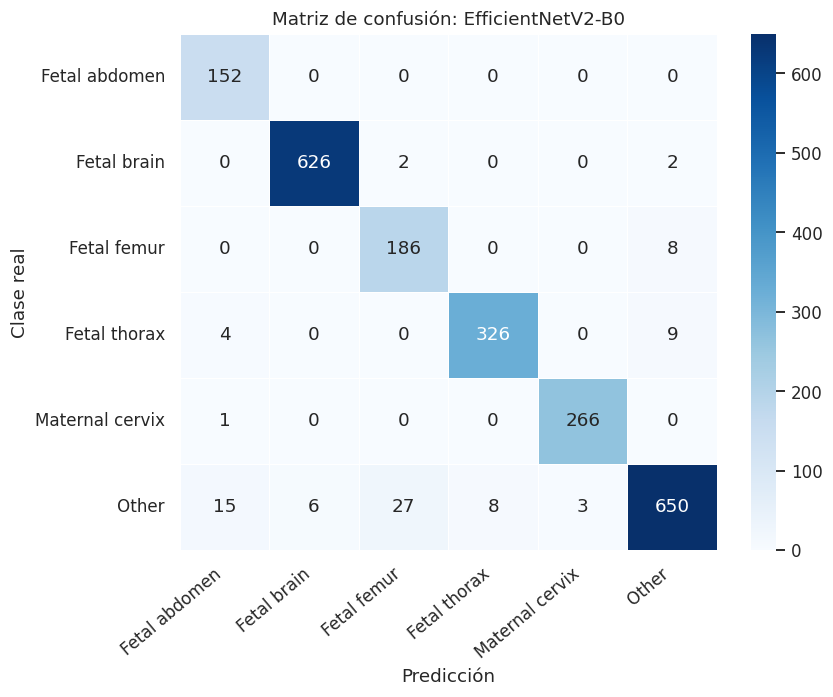

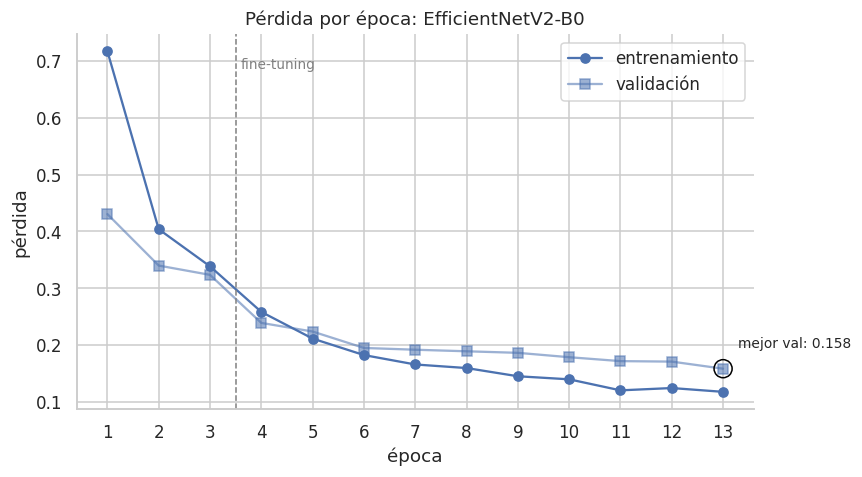

In [ ]:
plot_cm('EfficientNetV2-B0', 'Blues', 'cm_efficientnet.png')
plot_loss(info_efnet, 'EfficientNetV2-B0', 'loss_efficientnet.png')

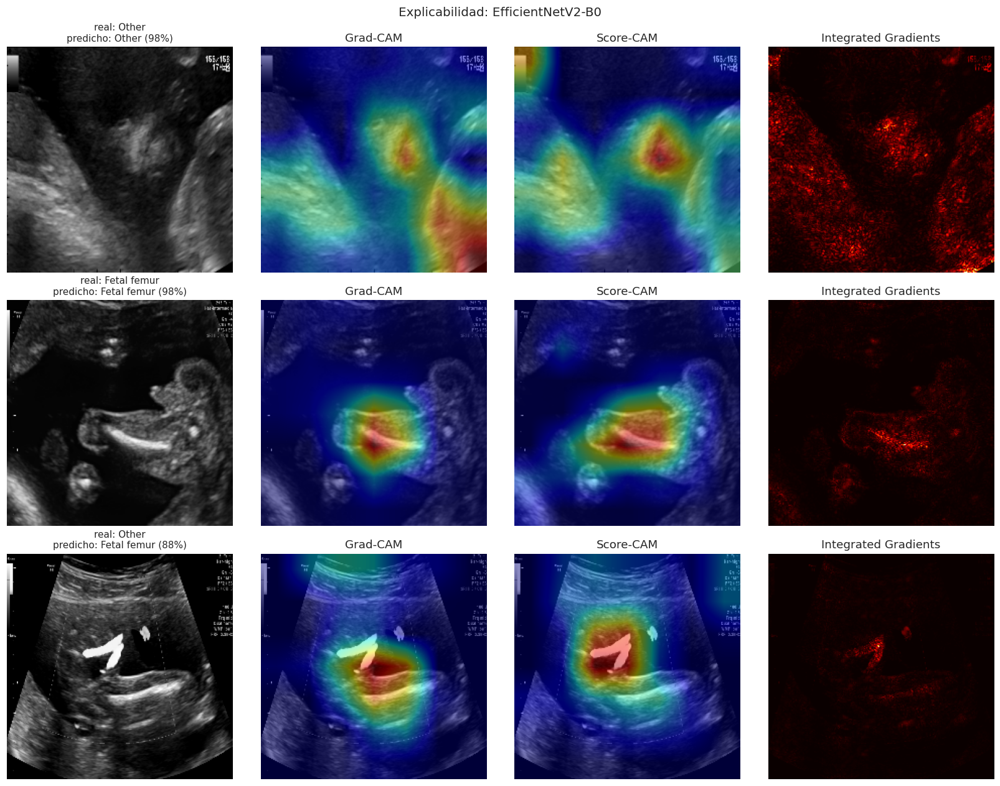

In [ ]:
XAI_IDX = pick_xai_samples(RESULTS['EfficientNetV2-B0']['probs'])
xai_cnn(model_EfNetB0, 'EfficientNetV2-B0', XAI_IDX, 'xai_efficientnet.png')

## 8. DenseNet-121

In [ ]:
# 8. DenseNet-121 (ahora con su preprocesamiento de ImageNet dentro del modelo)
RETRAIN_DENSENET = False
model_DenseNet121, info_dn = get_or_train_cnn('DenseNet121', DenseNet121,
                                              'DenseNet121_v3.keras', RETRAIN_DENSENET, ep_head=3, ep_fine=10,
                                              preprocess='imagenet_torch')
probs = model_DenseNet121.predict(test_ds, verbose=0)
evaluate_model(probs, 'DenseNet-121', model_DenseNet121.count_params())

Entrenando DenseNet121
29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/3
108/108 ━━━━━━━━━━━━━━━━━━━━ 49s 318ms/step - accuracy: 0.6872 - loss: 0.9022 - val_accuracy: 0.8490 - val_loss: 0.4715 - learning_rate: 0.0010
Epoch 2/3
108/108 ━━━━━━━━━━━━━━━━━━━━ 30s 276ms/step - accuracy: 0.8150 - loss: 0.5265 - val_accuracy: 0.8807 - val_loss: 0.3696 - learning_rate: 0.0010
Epoch 3/3
108/108 ━━━━━━━━━━━━━━━━━━━━ 30s 277ms/step - accuracy: 0.8421 - loss: 0.4325 - val_accuracy: 0.8896 - val_loss: 0.3364 - learning_rate: 0.0010
Restoring model weights from the end of the best epoch: 3.
Epoch 1/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 91s 562ms/step - accuracy: 0.8976 - loss: 0.2988 - val_accuracy: 0.9272 - val_loss: 0.2458 - learning_rate: 1.0000e-05
Epoch 2/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 60s 552ms/step - accuracy: 0.9207 - loss: 0.2123 - val_accuracy: 0.9338 - val_loss: 0.2109 - learning_rate: 1.0000e-05
Epoch 3/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 78s 515ms/step - accuracy: 0.9380 - loss: 0.174

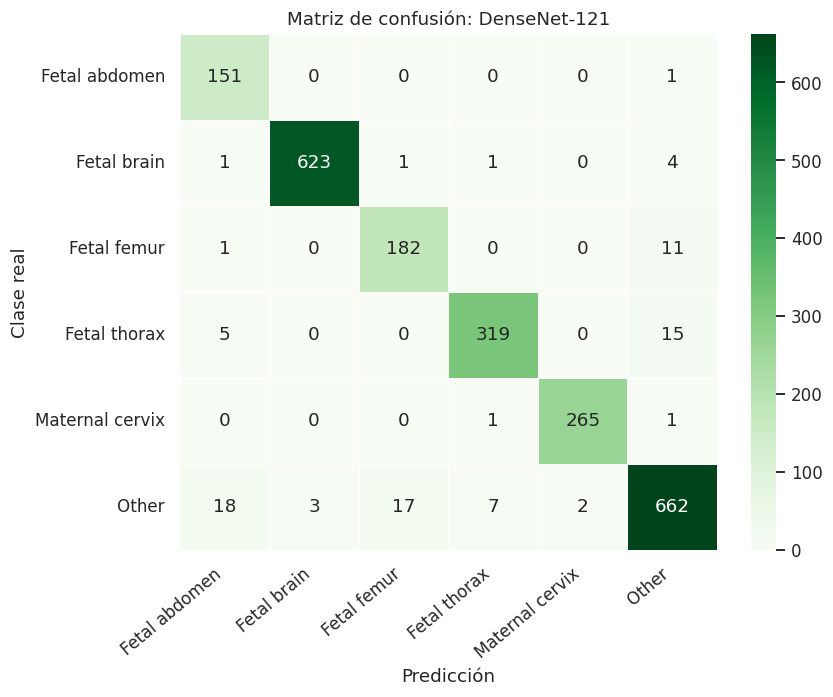

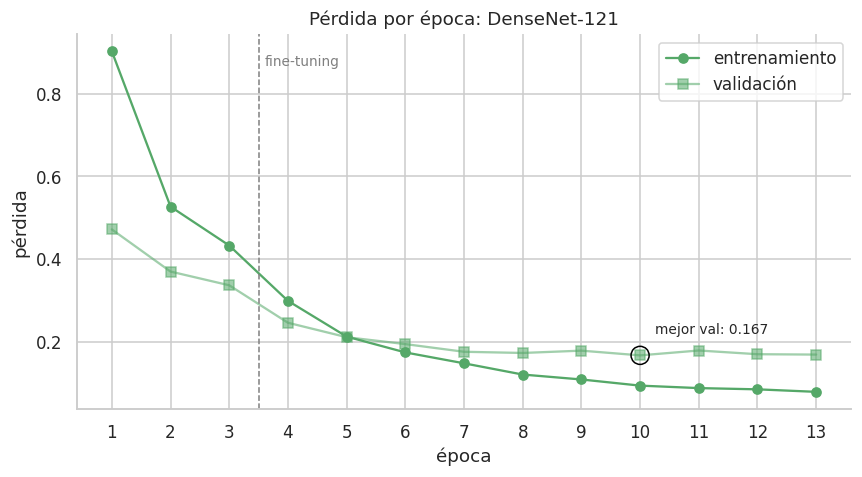

In [ ]:
plot_cm('DenseNet-121', 'Greens', 'cm_densenet.png')
plot_loss(info_dn, 'DenseNet-121', 'loss_densenet.png')

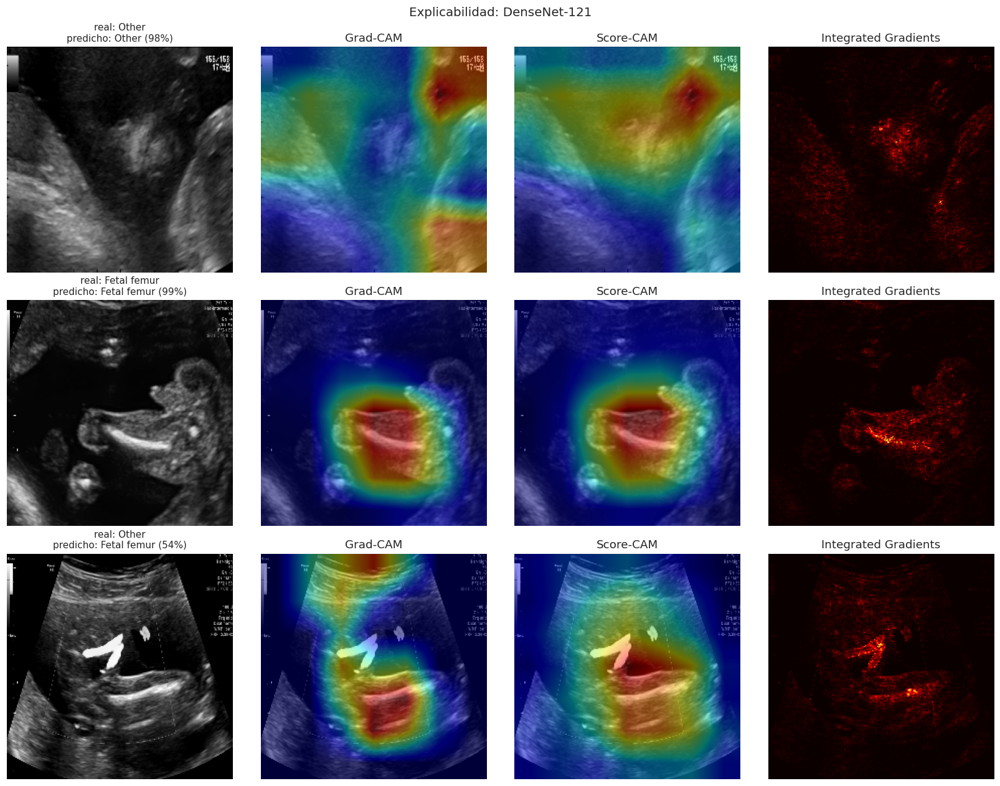

In [ ]:
xai_cnn(model_DenseNet121, 'DenseNet-121', XAI_IDX, 'xai_densenet.png')

## 9. Vision Transformer (ViT-B/16)

El ViT se implementó en PyTorch porque la librería de Hugging Face (`transformers`) dejó de dar soporte a TensorFlow desde su versión 5. Usa los mismos datos, aumentos, esquema de dos fases (cabeza y luego fine-tuning) y pesos de clase que las CNNs. Para explicarlo se usa Attention Rollout, ya que Grad-CAM necesita mapas convolucionales.

In [ ]:
# 9a. definición del modelo y funciones en pytorch
import torch.nn as nn, torch.nn.functional as F
from concurrent.futures import ThreadPoolExecutor
from transformers import ViTModel

device  = 'cuda' if torch.cuda.is_available() else 'cpu'
USE_AMP = device == 'cuda'
VIT_CKPT = 'google/vit-base-patch16-224-in21k'
torch.manual_seed(SEED)

class ViTClassifier(nn.Module):
    def __init__(self, n_classes, attn='sdpa'):
        super().__init__()
        self.vit = ViTModel.from_pretrained(VIT_CKPT, add_pooling_layer=False, attn_implementation=attn)
        h = self.vit.config.hidden_size
        self.head = nn.Sequential(nn.Linear(h, 64), nn.ReLU(), nn.Dropout(0.1), nn.Linear(64, n_classes))
    def forward(self, x, output_attentions=False):
        out = self.vit(pixel_values=x, output_attentions=output_attentions)
        logits = self.head(out.last_hidden_state[:, 0])      # token CLS
        return (logits, out.attentions) if output_attentions else logits

def to_input(xb_uint8):
    return xb_uint8.to(device, non_blocking=True).permute(0, 3, 1, 2).float() / 255.0

def normalize(x):
    return (x - 0.5) / 0.5

def gpu_augment(x):
    # volteo horizontal, rotación de +-30 grados y zoom de 0.2, igual que la capa augment de las CNNs
    B, dev = x.size(0), x.device
    ang  = (torch.rand(B, device=dev) * 2 - 1) * math.radians(30)
    zoom = 1 + (torch.rand(B, device=dev) * 2 - 1) * 0.2
    fh = torch.where(torch.rand(B, device=dev) < 0.5, -1.0, 1.0)
    fv = torch.ones(B, device=dev)          # sin volteo vertical: las CNNs solo voltean en horizontal
    cos, sin = torch.cos(ang) / zoom, torch.sin(ang) / zoom
    theta = torch.zeros(B, 2, 3, device=dev)
    theta[:, 0, 0] = cos * fh; theta[:, 0, 1] = -sin * fh
    theta[:, 1, 0] = sin * fv; theta[:, 1, 1] = cos * fv
    grid = F.affine_grid(theta, list(x.shape), align_corners=False)
    return F.grid_sample(x, grid, padding_mode='reflection', align_corners=False)

def load_many(paths, workers=8):
    def _one(p):
        img = cv2.imread(str(p))
        if img is None:
            raise FileNotFoundError(str(p))
        return cv2.resize(cv2.cvtColor(img, cv2.COLOR_BGR2RGB), (IMG_SIZE, IMG_SIZE))
    with ThreadPoolExecutor(workers) as ex:
        return np.stack(list(tqdm(ex.map(_one, list(paths)), total=len(paths), leave=False)))

@torch.no_grad()
def predict_probs(model, X, bs=64):
    model.eval(); out = []
    for i in range(0, len(X), bs):
        xb = normalize(to_input(torch.from_numpy(X[i:i+bs])))
        with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=USE_AMP):
            out.append(torch.softmax(model(xb).float(), dim=-1).cpu())
    return torch.cat(out).numpy()

def run_phase(model, params, lr, epochs, Xtr, ytr, Xva, yva, class_w, bs, patience, tag):
    opt    = torch.optim.Adam(params, lr=lr)
    sched  = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.3, patience=1, min_lr=1e-7)
    scaler = torch.amp.GradScaler('cuda', enabled=USE_AMP)
    crit   = nn.CrossEntropyLoss(weight=class_w)
    best, best_state, bad, hist = float('inf'), None, 0, {'loss': [], 'val_loss': []}
    for ep in range(epochs):
        model.train(); perm = np.random.permutation(len(Xtr)); tot, n = 0.0, 0
        for i in range(0, len(perm), bs):
            idx = np.sort(perm[i:i+bs])
            x = normalize(gpu_augment(to_input(torch.from_numpy(Xtr[idx])))); y = torch.from_numpy(ytr[idx]).to(device)
            with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=USE_AMP):
                loss = crit(model(x).float(), y)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tot += loss.item() * len(idx); n += len(idx)
        probs = predict_probs(model, Xva)
        vloss = float(F.nll_loss(torch.log(torch.from_numpy(probs) + 1e-8), torch.from_numpy(yva)))
        vacc  = float((probs.argmax(1) == yva).mean())
        sched.step(vloss); hist['loss'].append(tot / n); hist['val_loss'].append(vloss)
        print(f'[{tag}] época {ep+1}/{epochs} | loss {tot/n:.4f} | val_loss {vloss:.4f} | val_acc {vacc:.4f}')
        if vloss < best - 1e-4:
            best, bad = vloss, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= patience:
                print(f'[{tag}] se detuvo por early stopping'); break
    if best_state is not None:
        model.load_state_dict(best_state)
    return hist
print('pytorch usando:', device)

pytorch usando: cuda


In [ ]:
# 9b. cargar o entrenar el ViT
RETRAIN_VIT = False
EPOCHS_HEAD_VIT, EPOCHS_FINE_VIT = 3, 10
LR_HEAD_VIT, LR_FINE_VIT = 1e-3, 1e-5
BS_VIT = 32
VIT_FILE = 'ViT_v3.pt'

Xte = load_many(df_test['filepath'])
model_ViT = ViTClassifier(num_classes).to(device)
path_vit, meta = find_file(VIT_FILE), load_meta()

if path_vit is not None and not RETRAIN_VIT:
    print('Cargando ViT desde', path_vit)
    model_ViT.load_state_dict(torch.load(path_vit, map_location=device))
    info_vit = meta.get('ViT', {})
else:
    print('Entrenando ViT')
    Xtr = load_many(tr_df['filepath']); ytr = tr_df['Plane'].map(class_to_idx).values.astype('int64')
    Xva = load_many(va_df['filepath']); yva = va_df['Plane'].map(class_to_idx).values.astype('int64')
    cw = torch.tensor([CLASS_WEIGHT[i] for i in range(num_classes)], dtype=torch.float32, device=device)
    t0 = time.time()
    for p in model_ViT.vit.parameters():
        p.requires_grad = False
    h1 = run_phase(model_ViT, model_ViT.head.parameters(), LR_HEAD_VIT, EPOCHS_HEAD_VIT, Xtr, ytr, Xva, yva, cw, BS_VIT, 2, 'cabeza')
    h2 = {'loss': [], 'val_loss': []}
    if EPOCHS_FINE_VIT > 0:
        for p in model_ViT.vit.parameters():
            p.requires_grad = True
        h2 = run_phase(model_ViT, model_ViT.parameters(), LR_FINE_VIT, EPOCHS_FINE_VIT, Xtr, ytr, Xva, yva, cw, BS_VIT, 3, 'fine-tuning')
    secs = time.time() - t0
    print(f'Tiempo de entrenamiento ViT: {secs/60:.1f} min')
    if (MODELS_DIR / VIT_FILE).exists():
        shutil.copy(MODELS_DIR / VIT_FILE, str(MODELS_DIR / VIT_FILE) + '.bak')
    torch.save(model_ViT.state_dict(), MODELS_DIR / VIT_FILE)
    info_vit = {'train_time_s': secs, 'loss': h1['loss'] + h2['loss'], 'val_loss': h1['val_loss'] + h2['val_loss'],
                'phase1_epochs': len(h1['loss'])}
    meta['ViT'] = info_vit; save_meta(meta)
    del Xtr, Xva

evaluate_model(predict_probs(model_ViT, Xte), 'ViT-B/16', sum(p.numel() for p in model_ViT.parameters()))

  0%|          | 0/2291 [00:00<?, ?it/s]

Cargando ViT desde /content/drive/MyDrive/IA2/proyecto_IA2/modelos/ViT_v3.pt
                 precision    recall  f1-score   support

  Fetal abdomen      0.899     0.993     0.944       152
    Fetal brain      0.987     0.995     0.991       630
    Fetal femur      0.916     0.959     0.937       194
   Fetal thorax      0.979     0.956     0.967       339
Maternal cervix      0.985     1.000     0.993       267
          Other      0.972     0.937     0.954       709

       accuracy                          0.969      2291
      macro avg      0.956     0.973     0.964      2291
   weighted avg      0.969     0.969     0.969      2291



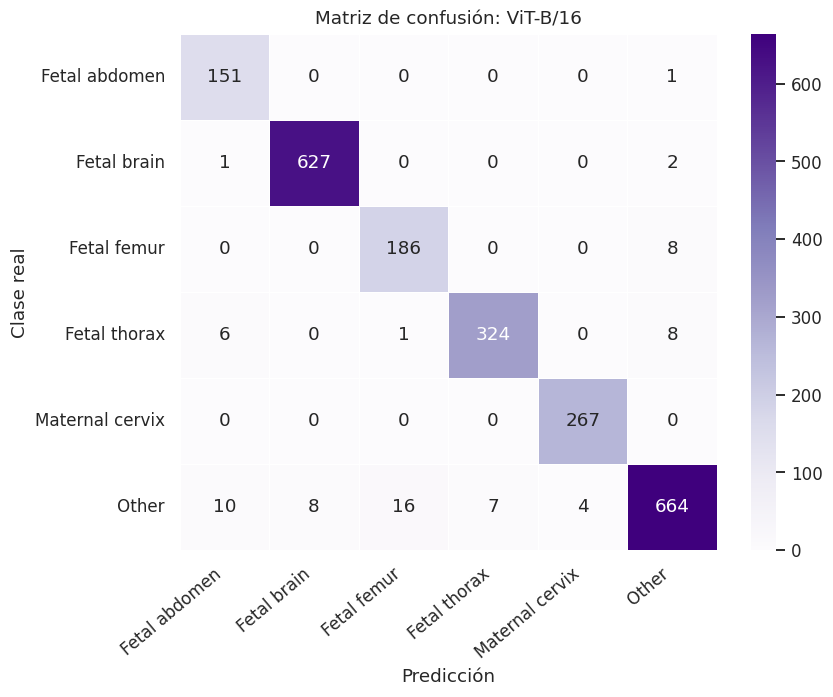

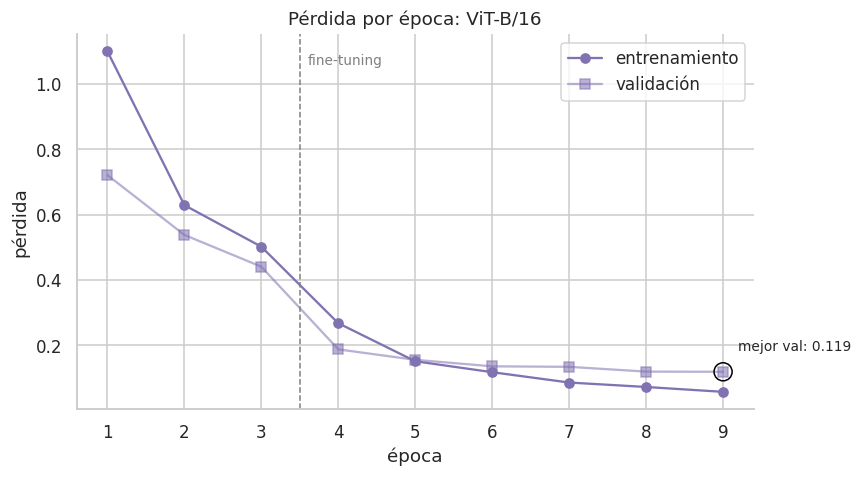

In [ ]:
plot_cm('ViT-B/16', 'Purples', 'cm_vit.png')
plot_loss(info_vit, 'ViT-B/16', 'loss_vit.png')

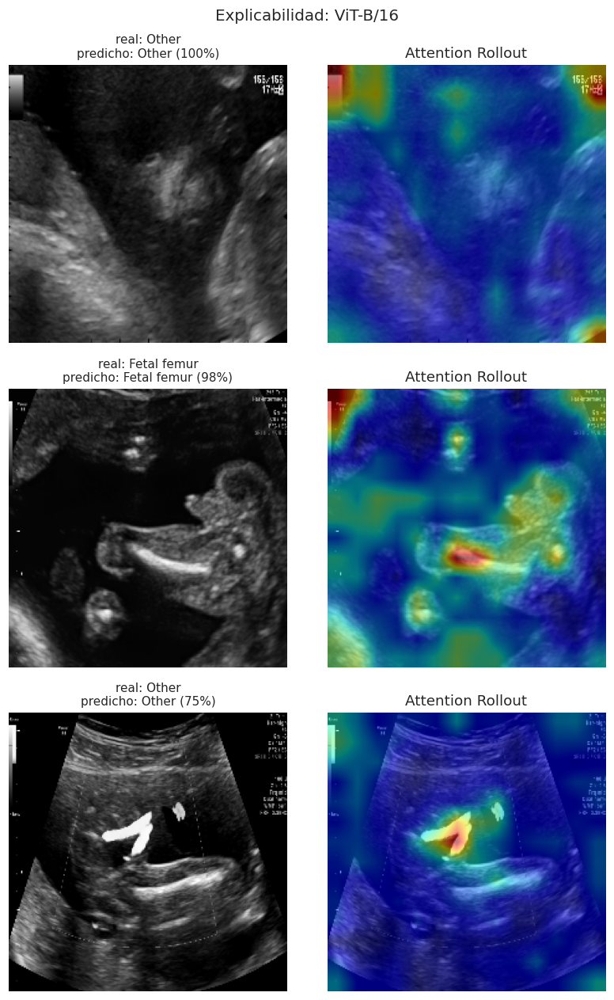

In [ ]:
# attention rollout: se promedian las cabezas, se suma la identidad y se encadenan las capas
@torch.no_grad()
def attention_rollout(model_eager, img_uint8):
    model_eager.eval()
    x = normalize(to_input(torch.from_numpy(img_uint8[None])))
    logits, atts = model_eager(x, output_attentions=True)
    T = atts[0].shape[-1]; result = torch.eye(T, device=x.device)
    for a in atts:
        a = a[0].float().mean(0) + torch.eye(T, device=x.device)
        a = a / a.sum(-1, keepdim=True); result = a @ result
    cls = result[0, 1:].cpu().numpy(); g = int(round(math.sqrt(cls.shape[0])))
    cls = cls.reshape(g, g); cls = cls / (cls.max() + 1e-8)
    return cls, torch.softmax(logits.float(), -1)[0].cpu().numpy()

# la atención solo se puede leer con la implementación "eager", por eso se copia el modelo a una instancia nueva
model_ViT_eager = ViTClassifier(num_classes, attn='eager').to(device)
model_ViT_eager.load_state_dict(model_ViT.state_dict())

fig, axes = plt.subplots(len(XAI_IDX), 2, figsize=(7.5, 3.9 * len(XAI_IDX)), squeeze=False)
for r, i in enumerate(XAI_IDX):
    row = df_test.iloc[i]; rgb = read_rgb(row['filepath'])
    cam, probs = attention_rollout(model_ViT_eager, rgb); p = int(np.argmax(probs))
    axes[r, 0].imshow(rgb); axes[r, 0].set_title(f"real: {row['Plane']}\npredicho: {classes[p]} ({probs[p]*100:.0f}%)", fontsize=10)
    axes[r, 1].imshow(rgb); axes[r, 1].imshow(cv2.resize(cam, (IMG_SIZE, IMG_SIZE)), cmap='jet', alpha=0.5)
    axes[r, 1].set_title('Attention Rollout')
    for a in axes[r]:
        a.axis('off')
plt.suptitle('Explicabilidad: ViT-B/16', fontsize=13); plt.tight_layout()
plt.savefig(FIGS_DIR / 'xai_vit.png', dpi=150); plt.show()
del model_ViT_eager

## 10. Comparación de los tres modelos

In [ ]:
# 10a. tabla comparativa
meta = load_meta()
TAGS = {'EfficientNetV2-B0': 'EfficientNetV2B0', 'DenseNet-121': 'DenseNet121', 'ViT-B/16': 'ViT'}
filas = []
for nombre, r in RESULTS.items():
    t = meta.get(TAGS[nombre], {}).get('train_time_s')
    filas.append({'Modelo': nombre, 'Accuracy': r['rep']['accuracy'], 'F1 macro': r['rep']['macro avg']['f1-score'],
                  'F1 ponderado': r['rep']['weighted avg']['f1-score'], 'Parámetros (M)': r['params'] / 1e6,
                  'Entrenamiento (min)': None if t is None else t / 60})
benchmark_df = pd.DataFrame(filas).set_index('Modelo')
benchmark_df.to_csv(DATASET_DIR / 'benchmark_modelos_v3.csv')
benchmark_df.style.format({'Accuracy': '{:.3f}', 'F1 macro': '{:.3f}', 'F1 ponderado': '{:.3f}',
                           'Parámetros (M)': '{:.1f}', 'Entrenamiento (min)': '{:.0f}'}, na_rep='-') \
    .highlight_max(subset=['Accuracy', 'F1 macro', 'F1 ponderado'], color='#cfe8cf')

,Accuracy,F1 macro,F1 ponderado,Parámetros (M),Entrenamiento (min)
Modelo,,,,,
EfficientNetV2-B0,0.963,0.957,0.963,6.0,41
DenseNet-121,0.961,0.955,0.961,7.1,12
ViT-B/16,0.969,0.964,0.969,85.8,9


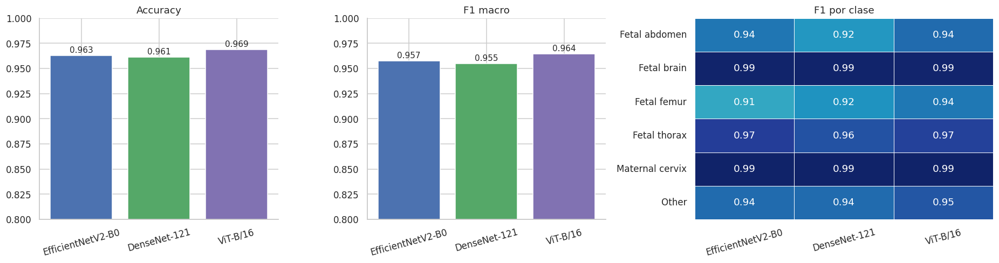

In [ ]:
# 10b. accuracy, F1 macro y F1 por clase
nombres = list(RESULTS)
f1_clase = pd.DataFrame({n: [RESULTS[n]['rep'][c]['f1-score'] for c in classes] for n in nombres}, index=classes)
f1_clase.to_csv(DATASET_DIR / 'benchmark_f1_por_clase_v3.csv')

fig, ax = plt.subplots(1, 3, figsize=(17, 4.6), gridspec_kw={'width_ratios': [1, 1, 1.25]})
for a, m_ in zip(ax[:2], ['Accuracy', 'F1 macro']):
    vals = benchmark_df[m_]
    a.bar(nombres, vals, color=[COLORES[n] for n in nombres])
    a.set_ylim(0.8, 1.0); a.set_title(m_); a.tick_params(axis='x', rotation=15)
    for i, v in enumerate(vals):
        a.text(i, v + 0.003, f'{v:.3f}', ha='center', fontsize=10)
sns.heatmap(f1_clase, annot=True, fmt='.2f', cmap='YlGnBu', vmin=0.8, vmax=1.0, ax=ax[2], cbar=False, linewidths=.5)
ax[2].set_title('F1 por clase'); ax[2].tick_params(axis='x', rotation=15)
plt.tight_layout(); plt.savefig(FIGS_DIR / 'benchmark.png', dpi=150); plt.show()

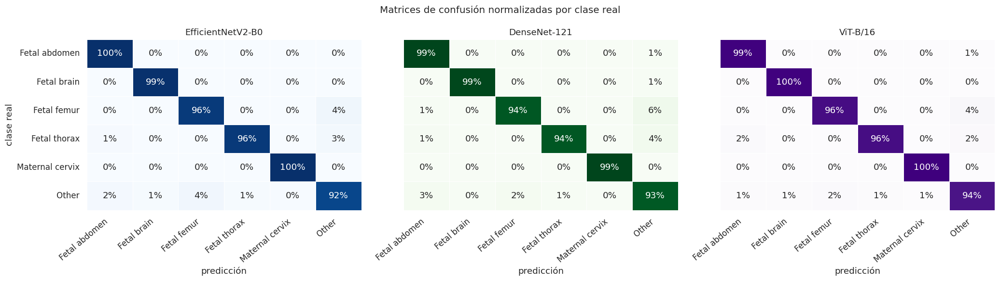

In [ ]:
# 10c. matrices de confusión en porcentaje, una al lado de la otra
cmaps = {'EfficientNetV2-B0': 'Blues', 'DenseNet-121': 'Greens', 'ViT-B/16': 'Purples'}
fig, axes = plt.subplots(1, 3, figsize=(19, 5.4))
for a, n in zip(axes, nombres):
    cm = confusion_matrix(true_labels, RESULTS[n]['pred'], normalize='true')
    sns.heatmap(cm, annot=True, fmt='.0%', cmap=cmaps[n], vmin=0, vmax=1, cbar=False, ax=a,
                xticklabels=classes, yticklabels=classes if n == nombres[0] else False, linewidths=.5, linecolor='white')
    a.set_title(n); a.set_xlabel('predicción'); a.tick_params(axis='x', rotation=40)
    for t in a.get_xticklabels():
        t.set_ha('right')
axes[0].set_ylabel('clase real')
plt.suptitle('Matrices de confusión normalizadas por clase real', fontsize=13)
plt.tight_layout(); plt.savefig(FIGS_DIR / 'cm_comparativa.png', dpi=150); plt.show()

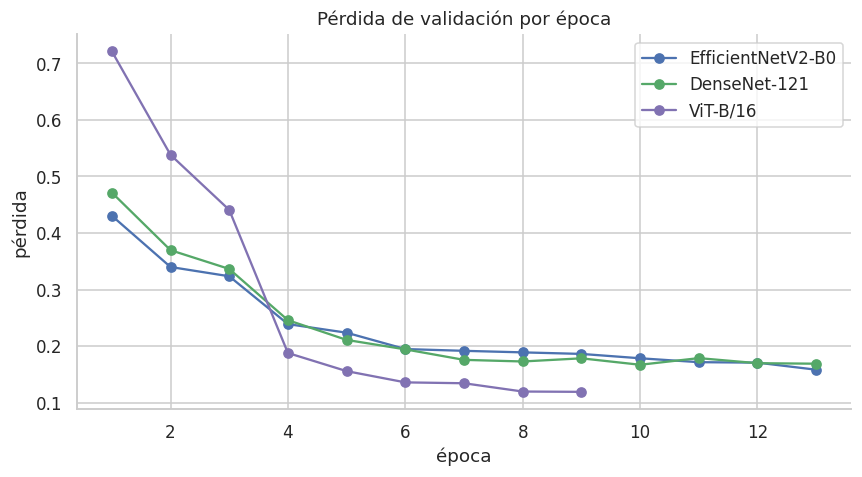

Modelos sin historial guardado: []


In [ ]:
# 10d. curvas de pérdida de validación de los modelos que tienen historial
fig, ax = plt.subplots(figsize=(8, 4.5))
hay = False
for n in nombres:
    info = meta.get(TAGS[n], {})
    if info.get('val_loss'):
        hay = True
        ep = np.arange(1, len(info['val_loss']) + 1)
        ax.plot(ep, info['val_loss'], '-o', color=COLORES[n], label=n)
if hay:
    ax.set_title('Pérdida de validación por época'); ax.set_xlabel('época'); ax.set_ylabel('pérdida')
    ax.legend(); plt.tight_layout(); plt.savefig(FIGS_DIR / 'loss_comparativa.png', dpi=150); plt.show()
else:
    plt.close(fig)
print('Modelos sin historial guardado:', [n for n in nombres if not meta.get(TAGS[n], {}).get('val_loss')])

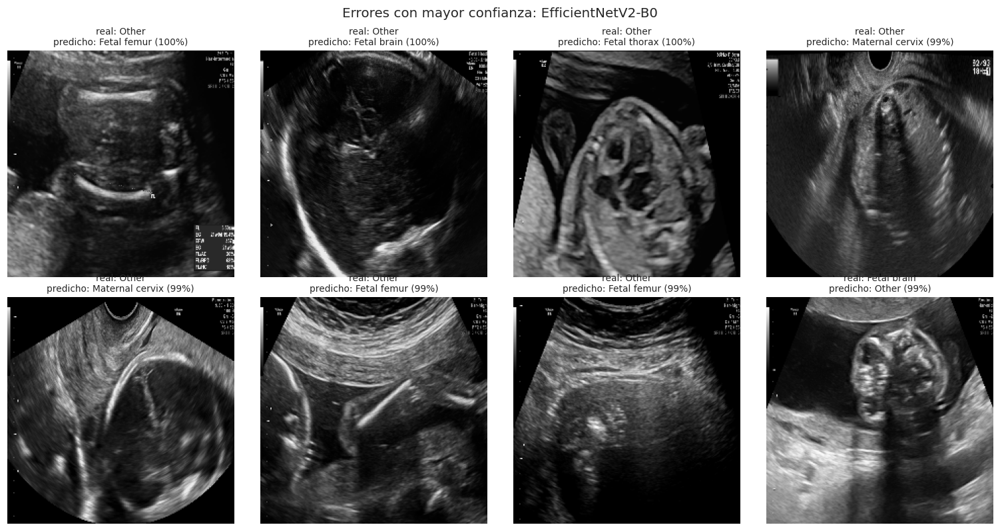

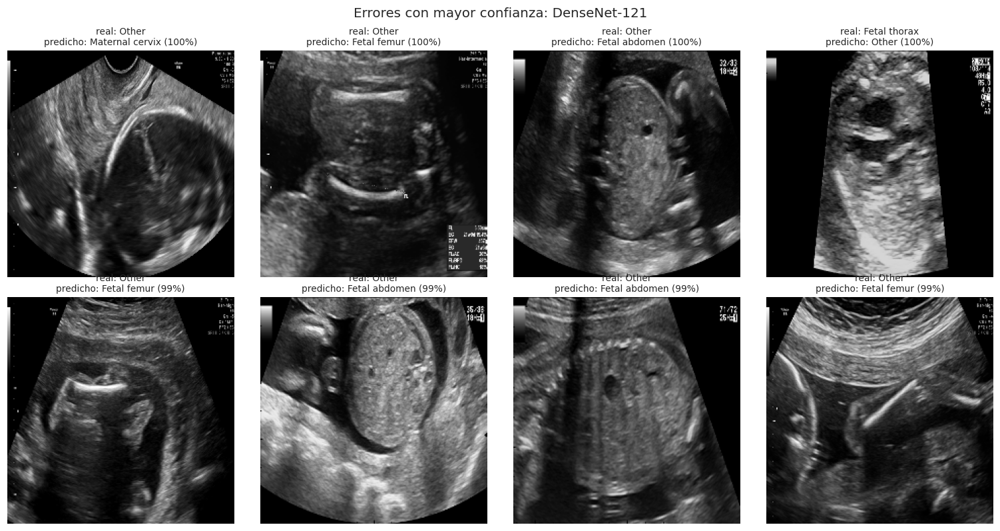

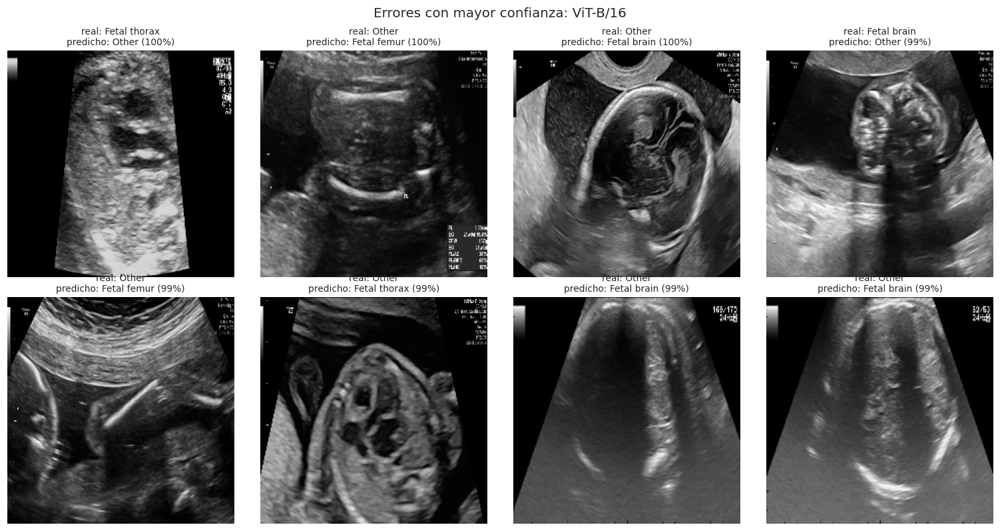

In [ ]:
# 10e. errores con más confianza de cada modelo
def galeria_errores(nombre, n=8):
    r = RESULTS[nombre]
    err = np.where(r['pred'] != true_labels)[0]
    err = err[np.argsort(-r['probs'][err, r['pred'][err]])][:n]
    fig, axes = plt.subplots(2, 4, figsize=(14, 7.4))
    for a, i in zip(axes.ravel(), err):
        a.imshow(read_rgb(df_test.iloc[i]['filepath']))
        a.set_title(f"real: {classes[true_labels[i]]}\npredicho: {classes[r['pred'][i]]} ({r['probs'][i, r['pred'][i]]*100:.0f}%)", fontsize=9)
        a.axis('off')
    for a in axes.ravel()[len(err):]:
        a.axis('off')
    plt.suptitle(f'Errores con mayor confianza: {nombre}', fontsize=13); plt.tight_layout()
    plt.savefig(FIGS_DIR / f"errores_{TAGS[nombre].lower()}.png", dpi=150); plt.show()

for n in nombres:
    galeria_errores(n)

,Confianza media en aciertos,Confianza media en errores,Predicciones con confianza > 90 %,ECE
Modelo,,,,
EfficientNetV2-B0,0.972,0.759,0.898,0.007
DenseNet-121,0.979,0.788,0.916,0.015
ViT-B/16,0.981,0.755,0.930,0.005


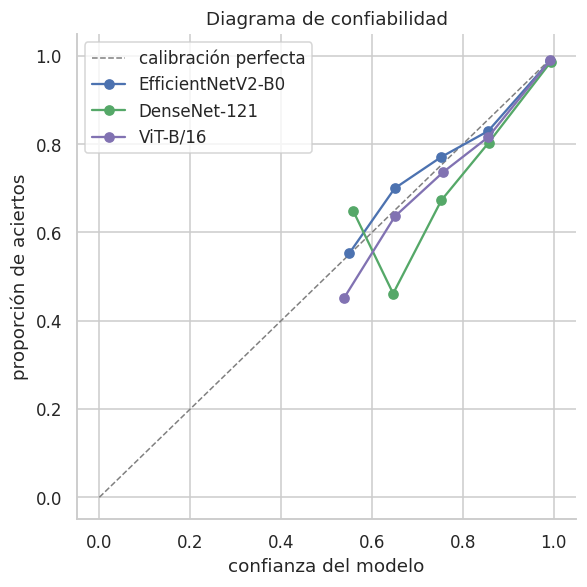

In [ ]:
# 10g. confianza de las predicciones: qué tan seguro está cada modelo cuando acierta y cuando falla
def ece_score(probs, y, bins=10):
    # error de calibración esperado: diferencia media entre la confianza y la proporción real de aciertos
    conf, ok = probs.max(1), (probs.argmax(1) == y).astype(float)
    edges, e = np.linspace(0, 1, bins + 1), 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            e += m.mean() * abs(ok[m].mean() - conf[m].mean())
    return e

filas = []
for n in nombres:
    p = RESULTS[n]['probs']; conf = p.max(1); ok = RESULTS[n]['pred'] == true_labels
    filas.append({'Modelo': n, 'Confianza media en aciertos': conf[ok].mean(), 'Confianza media en errores': conf[~ok].mean(),
                  'Predicciones con confianza > 90 %': (conf > 0.9).mean(), 'ECE': ece_score(p, true_labels)})
conf_df = pd.DataFrame(filas).set_index('Modelo')
conf_df.to_csv(DATASET_DIR / 'benchmark_confianza_v3.csv')
display(conf_df.style.format('{:.3f}'))

fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.plot([0, 1], [0, 1], '--', color='gray', lw=1, label='calibración perfecta')
edges = np.linspace(0, 1, 11)
for n in nombres:
    p = RESULTS[n]['probs']; conf = p.max(1); ok = RESULTS[n]['pred'] == true_labels
    xs, ys = [], []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.sum() >= 10:
            xs.append(conf[m].mean()); ys.append(ok[m].mean())
    ax.plot(xs, ys, '-o', color=COLORES[n], label=n)
ax.set_xlabel('confianza del modelo'); ax.set_ylabel('proporción de aciertos'); ax.set_title('Diagrama de confiabilidad')
ax.legend(); plt.tight_layout(); plt.savefig(FIGS_DIR / 'confiabilidad.png', dpi=150); plt.show()

In [ ]:
# 10f. comparación con la primera versión (split por imagen), para ver cuánto cambia al separar por paciente
antes = pd.DataFrame({'Accuracy (split por imagen)': {'EfficientNetV2-B0': 0.9645, 'DenseNet-121': 0.9272, 'ViT-B/16': 0.9737},
                      'F1 macro (split por imagen)': {'EfficientNetV2-B0': 0.9588, 'DenseNet-121': 0.9113, 'ViT-B/16': 0.9696}})
ahora = benchmark_df[['Accuracy', 'F1 macro']].rename(columns={'Accuracy': 'Accuracy (split por paciente)', 'F1 macro': 'F1 macro (split por paciente)'})
comp = antes.join(ahora)[['Accuracy (split por imagen)', 'Accuracy (split por paciente)', 'F1 macro (split por imagen)', 'F1 macro (split por paciente)']]
comp.style.format('{:.3f}')

,Accuracy (split por imagen),Accuracy (split por paciente),F1 macro (split por imagen),F1 macro (split por paciente)
EfficientNetV2-B0,0.965,0.963,0.959,0.957
DenseNet-121,0.927,0.961,0.911,0.955
ViT-B/16,0.974,0.969,0.970,0.964


## 10 bis. Análisis estadístico, eficiencia, clase Other y explicabilidad cuantificada

Estas celdas no reentrenan nada: usan las predicciones que ya están en `RESULTS` y los modelos cargados. Se ejecutan después de las secciones 7 a 9 y de la celda 10a.

,Accuracy,Accuracy IC95 inf,Accuracy IC95 sup,F1 macro,F1 macro IC95 inf,F1 macro IC95 sup
Modelo,,,,,,
EfficientNetV2-B0,0.963,0.953,0.972,0.957,0.945,0.968
DenseNet-121,0.961,0.953,0.969,0.955,0.944,0.964
ViT-B/16,0.969,0.961,0.976,0.964,0.955,0.973


,Solo acierta el 1.º,Solo acierta el 2.º,p McNemar,p ajustado (Bonferroni),Dif. accuracy,IC95 dif. accuracy,IC95 dif. F1 macro,¿Diferencia significativa? (p aj. < 0.05)
Comparación,,,,,,,,
EfficientNetV2-B0 vs DenseNet-121,36,32,0.7163,1.0000,+0.002,"[-0.005, +0.010]","[-0.006, +0.011]",no
EfficientNetV2-B0 vs ViT-B/16,31,44,0.1654,0.4963,-0.006,"[-0.014, +0.003]","[-0.017, +0.003]",no
DenseNet-121 vs ViT-B/16,28,45,0.0604,0.1811,-0.007,"[-0.015, -0.001]","[-0.018, -0.002]",no


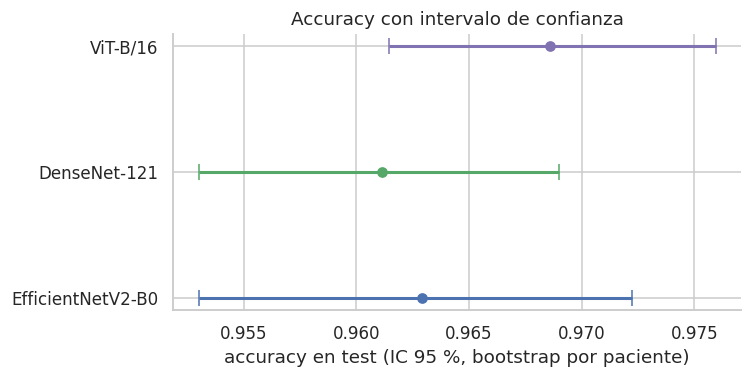

In [ ]:
# 10h. ¿las diferencias entre modelos son reales? McNemar y bootstrap por paciente
from scipy.stats import binomtest
from itertools import combinations
N_BOOT = 2000
nombres = list(RESULTS)
K = num_classes

def macro_f1(y, p):
    cm = np.bincount(y * K + p, minlength=K * K).reshape(K, K)
    tp = np.diag(cm).astype(float); fp = cm.sum(0) - tp; fn = cm.sum(1) - tp
    den = 2 * tp + fp + fn
    return float(np.mean(np.where(den > 0, 2 * tp / np.maximum(den, 1), 0.0)))

# bootstrap por paciente: se remuestrean pacientes completos, porque las imágenes de un mismo paciente no son independientes
codes, uniq = pd.factorize(pac_test)
grupos = [np.where(codes == g)[0] for g in range(len(uniq))]
rng = np.random.default_rng(SEED)
boot_idx = [np.concatenate([grupos[g] for g in rng.integers(0, len(grupos), len(grupos))]) for _ in range(N_BOOT)]

preds = {n: RESULTS[n]['pred'] for n in nombres}
boot = {n: {'acc': np.array([(preds[n][ix] == true_labels[ix]).mean() for ix in boot_idx]),
            'f1':  np.array([macro_f1(true_labels[ix], preds[n][ix]) for ix in boot_idx])} for n in nombres}

# intervalos de confianza del 95 % de cada modelo
filas = []
for n in nombres:
    a, f = boot[n]['acc'], boot[n]['f1']
    filas.append({'Modelo': n,
                  'Accuracy': (preds[n] == true_labels).mean(), 'Accuracy IC95 inf': np.percentile(a, 2.5), 'Accuracy IC95 sup': np.percentile(a, 97.5),
                  'F1 macro': macro_f1(true_labels, preds[n]), 'F1 macro IC95 inf': np.percentile(f, 2.5), 'F1 macro IC95 sup': np.percentile(f, 97.5)})
ic_df = pd.DataFrame(filas).set_index('Modelo')
display(ic_df.style.format('{:.3f}'))

# comparaciones por pares: McNemar exacto (con corrección de Bonferroni) y diferencia con IC95 por bootstrap
pares = list(combinations(nombres, 2))
filas = []
for a_, b_ in pares:
    ok_a, ok_b = preds[a_] == true_labels, preds[b_] == true_labels
    solo_a, solo_b = int((ok_a & ~ok_b).sum()), int((~ok_a & ok_b).sum())
    p = binomtest(min(solo_a, solo_b), solo_a + solo_b, 0.5).pvalue if solo_a + solo_b > 0 else 1.0
    d_acc = boot[a_]['acc'] - boot[b_]['acc']; d_f1 = boot[a_]['f1'] - boot[b_]['f1']
    filas.append({'Comparación': f'{a_} vs {b_}', 'Solo acierta el 1.º': solo_a, 'Solo acierta el 2.º': solo_b,
                  'p McNemar': p, 'p ajustado (Bonferroni)': min(1.0, p * len(pares)),
                  'Dif. accuracy': (ok_a.mean() - ok_b.mean()),
                  'IC95 dif. accuracy': f'[{np.percentile(d_acc, 2.5):+.3f}, {np.percentile(d_acc, 97.5):+.3f}]',
                  'IC95 dif. F1 macro': f'[{np.percentile(d_f1, 2.5):+.3f}, {np.percentile(d_f1, 97.5):+.3f}]'})
mc_df = pd.DataFrame(filas).set_index('Comparación')
mc_df['¿Diferencia significativa? (p aj. < 0.05)'] = np.where(mc_df['p ajustado (Bonferroni)'] < 0.05, 'sí', 'no')
display(mc_df.style.format({'p McNemar': '{:.4f}', 'p ajustado (Bonferroni)': '{:.4f}', 'Dif. accuracy': '{:+.3f}'}))
ic_df.to_csv(DATASET_DIR / 'benchmark_ic95_v3.csv'); mc_df.to_csv(DATASET_DIR / 'benchmark_mcnemar_v3.csv')

fig, ax = plt.subplots(figsize=(7, 3.6))
for k, n in enumerate(nombres):
    r = ic_df.loc[n]
    ax.errorbar(r['Accuracy'], k, xerr=[[r['Accuracy'] - r['Accuracy IC95 inf']], [r['Accuracy IC95 sup'] - r['Accuracy']]],
                fmt='o', color=COLORES[n], capsize=5, lw=2)
ax.set_yticks(range(len(nombres))); ax.set_yticklabels(nombres); ax.set_xlabel('accuracy en test (IC 95 %, bootstrap por paciente)')
ax.set_title('Accuracy con intervalo de confianza'); plt.tight_layout(); plt.savefig(FIGS_DIR / 'accuracy_ic95.png', dpi=150); plt.show()

  0%|          | 0/256 [00:00<?, ?it/s]

,Parámetros (M),Tamaño del archivo (MB),Inferencia (ms/imagen),Imágenes/s,Accuracy,F1 macro,Parámetros vs el más pequeño (x)
Modelo,,,,,,,
EfficientNetV2-B0,6.0,119,12.4,81,0.963,0.957,1.0
DenseNet-121,7.1,141,20.4,49,0.961,0.955,1.2
ViT-B/16,85.8,343,3.1,324,0.969,0.964,14.3


Tiempo medido en cuda con lotes de 32, sin contar la lectura de imágenes; depende de la GPU asignada en Colab.


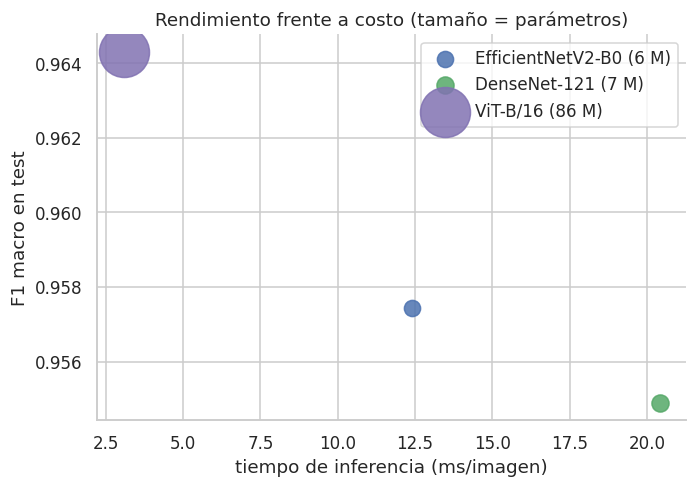

In [ ]:
# 10i. eficiencia: parámetros, tamaño del archivo y tiempo de inferencia
ARCHIVOS = {'EfficientNetV2-B0': 'EfficientNetV2B0_v3_SIN_DA.keras', 'DenseNet-121': 'DenseNet121_v3.keras', 'ViT-B/16': 'ViT_v3.pt'}
N_TIEMPO, BS_TIEMPO = 256, 32
muestra = load_many(df_test['filepath'].iloc[:N_TIEMPO])        # uint8, (N, 224, 224, 3)

def tiempo_cnn(model):
    xs = tf.convert_to_tensor(muestra.astype(np.float32))
    model(xs[:BS_TIEMPO], training=False).numpy()                # calentamiento
    t0 = time.perf_counter()
    for i in range(0, N_TIEMPO, BS_TIEMPO):
        model(xs[i:i+BS_TIEMPO], training=False).numpy()
    return (time.perf_counter() - t0) / N_TIEMPO * 1000

def tiempo_vit():
    predict_probs(model_ViT, muestra[:BS_TIEMPO], bs=BS_TIEMPO)   # calentamiento
    torch.cuda.synchronize() if device == 'cuda' else None
    t0 = time.perf_counter()
    predict_probs(model_ViT, muestra, bs=BS_TIEMPO)
    torch.cuda.synchronize() if device == 'cuda' else None
    return (time.perf_counter() - t0) / N_TIEMPO * 1000

MODELOS_OBJ = {'EfficientNetV2-B0': model_EfNetB0, 'DenseNet-121': model_DenseNet121, 'ViT-B/16': model_ViT}
filas = []
for n in RESULTS:
    ruta = find_file(ARCHIVOS[n])
    ms = tiempo_vit() if n == 'ViT-B/16' else tiempo_cnn(MODELOS_OBJ[n])
    filas.append({'Modelo': n, 'Parámetros (M)': RESULTS[n]['params'] / 1e6,
                  'Tamaño del archivo (MB)': ruta.stat().st_size / 1e6 if ruta else np.nan,
                  'Inferencia (ms/imagen)': ms, 'Imágenes/s': 1000 / ms,
                  'Accuracy': RESULTS[n]['rep']['accuracy'], 'F1 macro': RESULTS[n]['rep']['macro avg']['f1-score']})
efi_df = pd.DataFrame(filas).set_index('Modelo')
ref = efi_df['Parámetros (M)'].min()
efi_df['Parámetros vs el más pequeño (x)'] = efi_df['Parámetros (M)'] / ref
efi_df.to_csv(DATASET_DIR / 'benchmark_eficiencia_v3.csv')
display(efi_df.style.format({'Parámetros (M)': '{:.1f}', 'Tamaño del archivo (MB)': '{:.0f}', 'Inferencia (ms/imagen)': '{:.1f}',
                             'Imágenes/s': '{:.0f}', 'Accuracy': '{:.3f}', 'F1 macro': '{:.3f}', 'Parámetros vs el más pequeño (x)': '{:.1f}'}, na_rep='-'))
print(f'Tiempo medido en {device} con lotes de {BS_TIEMPO}, sin contar la lectura de imágenes; depende de la GPU asignada en Colab.')

fig, ax = plt.subplots(figsize=(6.5, 4.6))
for n, r in efi_df.iterrows():
    ax.scatter(r['Inferencia (ms/imagen)'], r['F1 macro'], s=40 + 12 * r['Parámetros (M)'], color=COLORES[n], alpha=.85, label=f"{n} ({r['Parámetros (M)']:.0f} M)")
ax.set_xlabel('tiempo de inferencia (ms/imagen)'); ax.set_ylabel('F1 macro en test'); ax.set_title('Rendimiento frente a costo (tamaño = parámetros)')
ax.legend(); plt.tight_layout(); plt.savefig(FIGS_DIR / 'eficiencia.png', dpi=150); plt.show()

Clase tratada como "Other": Other


,Errores totales,Errores que involucran Other,% de los errores,Precisión Other,Recall Other,F1 Other
Modelo,,,,,,
EfficientNetV2-B0,85,78,91.8,0.972,0.917,0.943
DenseNet-121,89,79,88.8,0.954,0.934,0.944
ViT-B/16,72,64,88.9,0.972,0.937,0.954


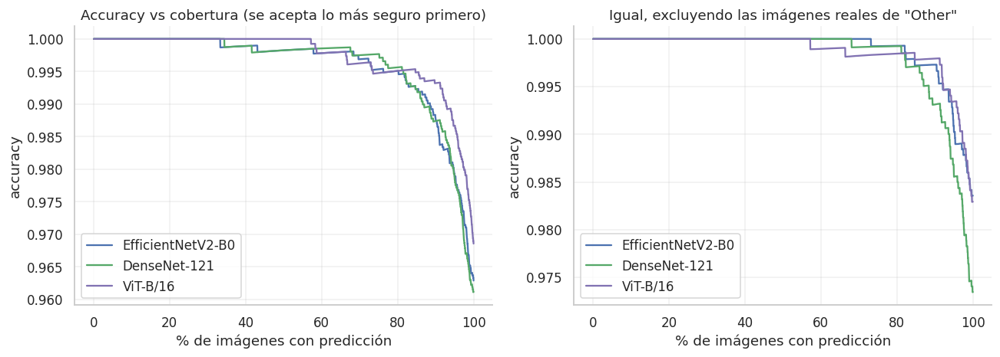

In [ ]:
# 10j. clase Other y rechazo por baja confianza ("no estoy seguro")
OTHER = next((c for c in classes if c.lower() == 'other'), None)
print('Clase tratada como "Other":', OTHER)
UMBRALES = [0.5, 0.7, 0.8, 0.9, 0.95]

# (a) cuánto pesa Other en los errores
filas = []
for n in nombres:
    pred = RESULTS[n]['pred']; err = pred != true_labels
    if OTHER is not None:
        o = class_to_idx[OTHER]
        con_other = err & ((true_labels == o) | (pred == o))
        r = RESULTS[n]['rep'][OTHER]
        filas.append({'Modelo': n, 'Errores totales': int(err.sum()), 'Errores que involucran Other': int(con_other.sum()),
                      '% de los errores': 100 * con_other.sum() / max(err.sum(), 1),
                      'Precisión Other': r['precision'], 'Recall Other': r['recall'], 'F1 Other': r['f1-score']})
if filas:
    other_df = pd.DataFrame(filas).set_index('Modelo')
    display(other_df.style.format({'% de los errores': '{:.1f}', 'Precisión Other': '{:.3f}', 'Recall Other': '{:.3f}', 'F1 Other': '{:.3f}'}))
    other_df.to_csv(DATASET_DIR / 'benchmark_other_v3.csv')

# (b) predicción selectiva: si la confianza es menor que el umbral, el sistema se abstiene
filas = []
for n in nombres:
    probs = RESULTS[n]['probs']; conf = probs.max(1); ok = RESULTS[n]['pred'] == true_labels
    for t in UMBRALES:
        acepta = conf >= t
        filas.append({'Modelo': n, 'Umbral': t, 'Cobertura (%)': 100 * acepta.mean(),
                      'Accuracy en las aceptadas': ok[acepta].mean() if acepta.any() else np.nan,
                      'Errores rechazados (%)': 100 * (~ok & ~acepta).sum() / max((~ok).sum(), 1),
                      'Aciertos rechazados (%)': 100 * (ok & ~acepta).sum() / max(ok.sum(), 1)})
rech_df = pd.DataFrame(filas).set_index(['Modelo', 'Umbral'])
display(rech_df.style.format('{:.1f}', subset=['Cobertura (%)', 'Errores rechazados (%)', 'Aciertos rechazados (%)']).format('{:.3f}', subset=['Accuracy en las aceptadas'], na_rep='-'))
rech_df.to_csv(DATASET_DIR / 'benchmark_rechazo_v3.csv')

fig, ax = plt.subplots(1, 2, figsize=(12, 4.4))
for n in nombres:
    probs = RESULTS[n]['probs']; conf = probs.max(1); ok = (RESULTS[n]['pred'] == true_labels)[np.argsort(-conf)]
    cob = np.arange(1, len(ok) + 1) / len(ok); acc = np.cumsum(ok) / np.arange(1, len(ok) + 1)
    ax[0].plot(100 * cob, acc, color=COLORES[n], label=n)
    if OTHER is not None:
        o = class_to_idx[OTHER]
        m = true_labels != o                      # accuracy sin contar las imágenes Other reales
        ok_o = ((RESULTS[n]['pred'] == true_labels) & m)[np.argsort(-conf)]
        ax[1].plot(100 * cob, np.cumsum(ok_o) / np.maximum(np.cumsum(m[np.argsort(-conf)]), 1), color=COLORES[n], label=n)
ax[0].set_title('Accuracy vs cobertura (se acepta lo más seguro primero)'); ax[0].set_xlabel('% de imágenes con predicción'); ax[0].set_ylabel('accuracy')
ax[1].set_title(f'Igual, excluyendo las imágenes reales de "{OTHER}"'); ax[1].set_xlabel('% de imágenes con predicción'); ax[1].set_ylabel('accuracy')
for a in ax:
    a.legend(); a.grid(alpha=.3)
plt.tight_layout(); plt.savefig(FIGS_DIR / 'rechazo_cobertura.png', dpi=150); plt.show()

EfficientNetV2-B0:   0%|          | 0/40 [00:00<?, ?it/s]

DenseNet-121:   0%|          | 0/40 [00:00<?, ?it/s]

/tmp/ipykernel_875/865278130.py:57: UserWarning: linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string "-o" (-> linestyle='-'). The keyword argument will take precedence.
  axes[r, c].plot(100 * FRACS, v[modo].mean(0), '-o', ms=3, color=COL_M[m], label=m, ls='--' if m == 'Aleatorio' else '-')


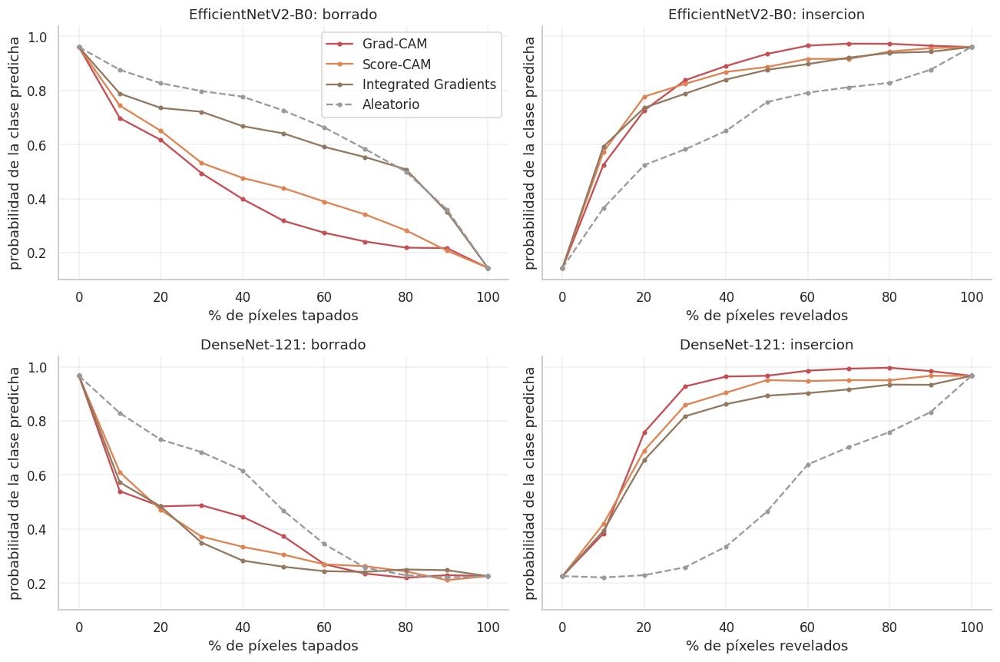

Calculado sobre 40 imágenes de test. El ViT (attention rollout) no se incluye porque su mapa no es comparable con estos tres.


In [ ]:
# 10k. explicabilidad cuantificada: pruebas de borrado e inserción (CNNs)
# Borrado: se tapan primero los píxeles que el mapa marca como más importantes; si el mapa es bueno, la confianza cae rápido (AUC bajo).
# Inserción: se parte de la imagen desenfocada y se revelan primero esos píxeles; si el mapa es bueno, la confianza sube rápido (AUC alto).
# "Aleatorio" es la referencia: un mapa sin información.
N_XAI_EVAL = 40
FRACS = np.linspace(0, 1, 11)
rng_x = np.random.default_rng(11)
IDX_EVAL = rng_x.choice(len(df_test), size=min(N_XAI_EVAL, len(df_test)), replace=False)

def auc(y, x=FRACS):
    return float(np.sum((y[1:] + y[:-1]) / 2 * np.diff(x)))

def curva(model, rgb, blur, hm, p, modo):
    orden = np.argsort(-hm.ravel()); n = orden.size
    imgs = []
    for f in FRACS:
        mask = np.zeros(n, bool); mask[orden[:int(round(f * n))]] = True
        mask = mask.reshape(IMG_SIZE, IMG_SIZE, 1)
        imgs.append(np.where(mask, blur, rgb) if modo == 'borrado' else np.where(mask, rgb, blur))
    return model(np.stack(imgs).astype(np.float32), training=False).numpy()[:, p]

def evaluar_cnn(model, nombre):
    conv_model, run_head = split_cnn(model)
    rng_r = np.random.default_rng(3)
    res = {m: {'borrado': [], 'insercion': []} for m in ['Grad-CAM', 'Score-CAM', 'Integrated Gradients', 'Aleatorio']}
    for i in tqdm(IDX_EVAL, desc=nombre):
        rgb = read_rgb(df_test.iloc[i]['filepath'])
        blur = cv2.GaussianBlur(rgb, (0, 0), sigmaX=12)
        batch = tf.convert_to_tensor(rgb[None].astype(np.float32))
        p = int(np.argmax(model(batch, training=False).numpy()[0]))
        mapas = {'Grad-CAM': cv2.resize(get_gradcam(batch, conv_model, run_head, p), (IMG_SIZE, IMG_SIZE)),
                 'Score-CAM': cv2.resize(get_scorecam(batch, conv_model, model, p), (IMG_SIZE, IMG_SIZE)),
                 'Integrated Gradients': get_integrated_gradients(model, batch, p),
                 'Aleatorio': rng_r.random((IMG_SIZE, IMG_SIZE))}
        for m, hm in mapas.items():
            res[m]['borrado'].append(curva(model, rgb, blur, hm, p, 'borrado'))
            res[m]['insercion'].append(curva(model, rgb, blur, hm, p, 'insercion'))
    return {m: {k: np.array(v) for k, v in d.items()} for m, d in res.items()}

CURVAS = {n: evaluar_cnn(m, n) for n, m in [('EfficientNetV2-B0', model_EfNetB0), ('DenseNet-121', model_DenseNet121)]}

filas = []
for n, d in CURVAS.items():
    for m, c in d.items():
        a_del = np.array([auc(y) for y in c['borrado']]); a_ins = np.array([auc(y) for y in c['insercion']])
        filas.append({'Modelo': n, 'Método': m, 'AUC borrado (menor es mejor)': a_del.mean(), '± borrado': a_del.std(),
                      'AUC inserción (mayor es mejor)': a_ins.mean(), '± inserción': a_ins.std(), 'Insertion - Deletion': (a_ins - a_del).mean()})
xai_df = pd.DataFrame(filas).set_index(['Modelo', 'Método'])
display(xai_df.style.format('{:.3f}'))
xai_df.to_csv(DATASET_DIR / 'benchmark_borrado_insercion_v3.csv')

COL_M = {'Grad-CAM': '#C44E52', 'Score-CAM': '#DD8452', 'Integrated Gradients': '#937860', 'Aleatorio': '#999999'}
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharey=True)
for r, (n, d) in enumerate(CURVAS.items()):
    for c, modo in enumerate(['borrado', 'insercion']):
        for m, v in d.items():
            axes[r, c].plot(100 * FRACS, v[modo].mean(0), '-o', ms=3, color=COL_M[m], label=m, ls='--' if m == 'Aleatorio' else '-')
        axes[r, c].set_title(f'{n}: {modo}'); axes[r, c].set_xlabel('% de píxeles ' + ('tapados' if modo == 'borrado' else 'revelados'))
        axes[r, c].set_ylabel('probabilidad de la clase predicha'); axes[r, c].grid(alpha=.3)
axes[0, 0].legend()
plt.tight_layout(); plt.savefig(FIGS_DIR / 'borrado_insercion.png', dpi=150); plt.show()
print(f'Calculado sobre {len(IDX_EVAL)} imágenes de test. El ViT (attention rollout) no se incluye porque su mapa no es comparable con estos tres.')

## 10 ter. Explicabilidad: Integrated Gradients en el ViT y mapas contra bordes y esquinas

La celda 10k cuantifica los mapas de las CNNs con pruebas de borrado e inserción y deja fuera al ViT. Aquí se calcula Integrated Gradients también en el ViT (el mismo método, la misma línea base negra y los mismos 30 pasos que en las CNNs), se repiten las pruebas de borrado e inserción con las mismas imágenes y se compara IG entre los tres modelos. La celda 10m mide cuánta masa de cada mapa cae en los bordes y las esquinas de la ecografía, donde suelen estar los rótulos del equipo. Necesitan los modelos cargados (secciones 7 a 9) y las celdas 10k (para `xai_df`, `IDX_EVAL` y `auc`).

In [ ]:
# 10l. Integrated Gradients en el ViT y borrado/inserción para el ViT
# IG se calcula igual que en las CNNs (línea base negra, 30 pasos, |imagen x gradiente promedio| promediado en canales),
# así la comparación entre los tres modelos es pareja. En el ViT el mapa se calcula sobre los píxeles, no sobre los parches.
def get_integrated_gradients_vit(model, rgb_uint8, pred_idx, num_steps=30, bs=8):
    model.eval()
    img = torch.from_numpy(rgb_uint8[None]).to(device).permute(0, 3, 1, 2).float() / 255.0      # (1, 3, H, W) en [0, 1]
    alphas = torch.linspace(0, 1, num_steps + 1, device=device).view(-1, 1, 1, 1)
    grads = []
    for i in range(0, num_steps + 1, bs):
        x = (alphas[i:i + bs] * img).requires_grad_(True)
        salida = model(normalize(x)).float()[:, pred_idx].sum()                                 # en float32, sin autocast
        g, = torch.autograd.grad(salida, x)
        grads.append(g.detach())
    avg = torch.cat(grads).mean(0, keepdim=True)
    hm = (img * avg).abs().mean(1)[0]
    return (hm / (hm.max() + 1e-8)).cpu().numpy().astype(np.float32)

def curva_vit(rgb, blur, hm, p, modo):
    orden = np.argsort(-hm.ravel()); n = orden.size
    imgs = []
    for f in FRACS:
        mask = np.zeros(n, bool); mask[orden[:int(round(f * n))]] = True
        mask = mask.reshape(IMG_SIZE, IMG_SIZE, 1)
        imgs.append(np.where(mask, blur, rgb) if modo == 'borrado' else np.where(mask, rgb, blur))
    return predict_probs(model_ViT, np.stack(imgs).astype(np.uint8))[:, p]

# la atención solo se puede leer con la implementación "eager": se usa una copia del modelo
model_ViT_eager = ViTClassifier(num_classes, attn='eager').to(device)
model_ViT_eager.load_state_dict(model_ViT.state_dict())

METODOS_VIT = ['Attention Rollout', 'Integrated Gradients', 'Aleatorio']
res_vit = {m: {'borrado': [], 'insercion': []} for m in METODOS_VIT}
rng_r = np.random.default_rng(3)
for i in tqdm(IDX_EVAL, desc='ViT-B/16'):                         # las mismas imágenes que en 10k
    rgb = read_rgb(df_test.iloc[i]['filepath'])
    blur = cv2.GaussianBlur(rgb, (0, 0), sigmaX=12)
    cam, probs_i = attention_rollout(model_ViT_eager, rgb); p = int(np.argmax(probs_i))
    mapas = {'Attention Rollout': cv2.resize(cam, (IMG_SIZE, IMG_SIZE)),
             'Integrated Gradients': get_integrated_gradients_vit(model_ViT, rgb, p),
             'Aleatorio': rng_r.random((IMG_SIZE, IMG_SIZE))}
    for m, hm in mapas.items():
        res_vit[m]['borrado'].append(curva_vit(rgb, blur, hm, p, 'borrado'))
        res_vit[m]['insercion'].append(curva_vit(rgb, blur, hm, p, 'insercion'))
res_vit = {m: {k: np.array(v) for k, v in d.items()} for m, d in res_vit.items()}
del model_ViT_eager
if device == 'cuda':
    torch.cuda.empty_cache()

filas = []
for m, c in res_vit.items():
    a_del = np.array([auc(y) for y in c['borrado']]); a_ins = np.array([auc(y) for y in c['insercion']])
    filas.append({'Modelo': 'ViT-B/16', 'Método': m, 'AUC borrado (menor es mejor)': a_del.mean(), '± borrado': a_del.std(),
                  'AUC inserción (mayor es mejor)': a_ins.mean(), '± inserción': a_ins.std(), 'Insertion - Deletion': (a_ins - a_del).mean()})
xai_all = pd.concat([xai_df, pd.DataFrame(filas).set_index(['Modelo', 'Método'])])
display(xai_all.style.format('{:.3f}'))
xai_all.to_csv(DATASET_DIR / 'benchmark_borrado_insercion_con_vit_v3.csv')

# la comparación pareja entre modelos es la de Integrated Gradients, que es el mismo método en los tres
ig = xai_all.xs('Integrated Gradients', level='Método')[['AUC borrado (menor es mejor)', 'AUC inserción (mayor es mejor)', 'Insertion - Deletion']]
print('Integrated Gradients en los tres modelos (mismo método, misma línea base):')
display(ig.style.format('{:.3f}'))

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
COL_V = {'Attention Rollout': '#8172B2', 'Integrated Gradients': '#937860', 'Aleatorio': '#999999'}
for a_, modo in zip(axes, ['borrado', 'insercion']):
    for m, v in res_vit.items():
        a_.plot(100 * FRACS, v[modo].mean(0), '-o', ms=3, color=COL_V[m], label=m, ls='--' if m == 'Aleatorio' else '-')
    a_.set_title(f'ViT-B/16: {modo}'); a_.set_xlabel('% de píxeles ' + ('tapados' if modo == 'borrado' else 'revelados'))
    a_.set_ylabel('probabilidad de la clase predicha'); a_.grid(alpha=.3)
axes[0].legend(); plt.tight_layout(); plt.savefig(FIGS_DIR / 'borrado_insercion_vit.png', dpi=150); plt.show()

# los mismos casos de las figuras de explicabilidad, ahora con IG también en el ViT
fig, axes = plt.subplots(len(XAI_IDX), 3, figsize=(11, 3.7 * len(XAI_IDX)), squeeze=False)
model_ViT_eager = ViTClassifier(num_classes, attn='eager').to(device); model_ViT_eager.load_state_dict(model_ViT.state_dict())
for r, i in enumerate(XAI_IDX):
    row = df_test.iloc[i]; rgb = read_rgb(row['filepath'])
    cam, probs_i = attention_rollout(model_ViT_eager, rgb); p = int(np.argmax(probs_i))
    ig_map = get_integrated_gradients_vit(model_ViT, rgb, p)
    axes[r, 0].imshow(rgb); axes[r, 0].set_title(f"real: {row['Plane']}\npredicho: {classes[p]} ({probs_i[p]*100:.0f}%)", fontsize=10)
    axes[r, 1].imshow(rgb); axes[r, 1].imshow(cv2.resize(cam, (IMG_SIZE, IMG_SIZE)), cmap='jet', alpha=0.5); axes[r, 1].set_title('Attention Rollout')
    axes[r, 2].imshow(ig_map, cmap='hot'); axes[r, 2].set_title('Integrated Gradients (ViT)')
    for a_ in axes[r]:
        a_.axis('off')
del model_ViT_eager
plt.suptitle('Explicabilidad del ViT-B/16: rollout e Integrated Gradients', fontsize=13); plt.tight_layout()
plt.savefig(FIGS_DIR / 'xai_vit_ig.png', dpi=150); plt.show()
print(f'Calculado sobre {len(IDX_EVAL)} imágenes de test (las mismas de 10k).')

EfficientNetV2-B0:   0%|          | 0/120 [00:00<?, ?it/s]

DenseNet-121:   0%|          | 0/120 [00:00<?, ?it/s]

ViT-B/16:   0%|          | 0/120 [00:00<?, ?it/s]

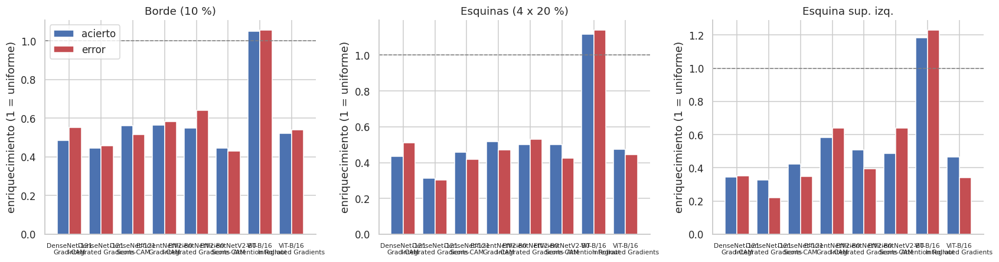

Errores analizados por modelo: {'DenseNet-121': 60, 'EfficientNetV2-B0': 60, 'ViT-B/16': 60} | el mapa "Aleatorio" sirve de referencia (debería quedar cerca de 1).
Lectura: un enriquecimiento claramente mayor que 1 en errores y no en aciertos sugiere que, cuando fallan, los mapas se apoyan en bordes o rótulos.


In [ ]:
# 10m. ¿los mapas caen sobre la imagen útil o sobre los bordes y las esquinas (texto del equipo, marcas)?
# No hay máscaras de anatomía en el dataset, así que esto no mide "cae sobre el fémur": mide cuánta masa del mapa cae en zonas
# donde las ecografías llevan rótulos y márgenes. Enriquecimiento = (fracción de la masa del mapa en la zona) / (fracción del área de la zona):
# 1,0 es un mapa uniforme; mayor que 1 es que el mapa pone más peso del esperado en esa zona.
N_OK_ANAT, N_ERR_ANAT = 60, 60          # por modelo: aciertos al azar y todos los errores (hasta ese tope)
yy, xx = np.mgrid[:IMG_SIZE, :IMG_SIZE]
B = int(round(0.10 * IMG_SIZE)); E = int(round(0.20 * IMG_SIZE))
ZONAS = {'Borde (10 %)': (yy < B) | (yy >= IMG_SIZE - B) | (xx < B) | (xx >= IMG_SIZE - B),
         'Esquinas (4 x 20 %)': ((yy < E) | (yy >= IMG_SIZE - E)) & ((xx < E) | (xx >= IMG_SIZE - E)),
         'Esquina sup. izq.': (yy < E) & (xx < E)}

def enriquecimiento(hm):
    hm = np.maximum(np.asarray(hm, dtype=np.float64), 0); total = hm.sum() + 1e-12
    return {z: float(hm[m].sum() / total / m.mean()) for z, m in ZONAS.items()}

def muestra_anat(nombre, seed=5):
    pred = RESULTS[nombre]['pred']; rng = np.random.default_rng(seed)
    ok, err = np.where(pred == true_labels)[0], np.where(pred != true_labels)[0]
    ok = rng.choice(ok, size=min(N_OK_ANAT, len(ok)), replace=False)
    err = rng.choice(err, size=min(N_ERR_ANAT, len(err)), replace=False) if len(err) else err
    return [(int(i), 'acierto') for i in ok] + [(int(i), 'error') for i in err]

filas = []
rng_alea = np.random.default_rng(9)
for nombre, modelo in [('EfficientNetV2-B0', model_EfNetB0), ('DenseNet-121', model_DenseNet121)]:
    conv_model, run_head = split_cnn(modelo)
    for i, res in tqdm(muestra_anat(nombre), desc=nombre):
        rgb = read_rgb(df_test.iloc[i]['filepath'])
        batch = tf.convert_to_tensor(rgb[None].astype(np.float32))
        p = int(RESULTS[nombre]['pred'][i])
        mapas = {'Grad-CAM': cv2.resize(get_gradcam(batch, conv_model, run_head, p), (IMG_SIZE, IMG_SIZE)),
                 'Score-CAM': cv2.resize(get_scorecam(batch, conv_model, modelo, p), (IMG_SIZE, IMG_SIZE)),
                 'Integrated Gradients': get_integrated_gradients(modelo, batch, p),
                 'Aleatorio': rng_alea.random((IMG_SIZE, IMG_SIZE))}
        for m, hm in mapas.items():
            filas.append({'Modelo': nombre, 'Método': m, 'Resultado': res, **enriquecimiento(hm)})

model_ViT_eager = ViTClassifier(num_classes, attn='eager').to(device); model_ViT_eager.load_state_dict(model_ViT.state_dict())
for i, res in tqdm(muestra_anat('ViT-B/16'), desc='ViT-B/16'):
    rgb = read_rgb(df_test.iloc[i]['filepath']); p = int(RESULTS['ViT-B/16']['pred'][i])
    cam, _ = attention_rollout(model_ViT_eager, rgb)
    mapas = {'Attention Rollout': cv2.resize(cam, (IMG_SIZE, IMG_SIZE)),
             'Integrated Gradients': get_integrated_gradients_vit(model_ViT, rgb, p),
             'Aleatorio': rng_alea.random((IMG_SIZE, IMG_SIZE))}
    for m, hm in mapas.items():
        filas.append({'Modelo': 'ViT-B/16', 'Método': m, 'Resultado': res, **enriquecimiento(hm)})
del model_ViT_eager
if device == 'cuda':
    torch.cuda.empty_cache()

anat_df = pd.DataFrame(filas)
tabla = anat_df.groupby(['Modelo', 'Método', 'Resultado'])[list(ZONAS)].mean()
tabla['imágenes'] = anat_df.groupby(['Modelo', 'Método', 'Resultado']).size()
display(tabla.style.format({**{z: '{:.2f}' for z in ZONAS}, 'imágenes': '{:.0f}'}))
tabla.to_csv(DATASET_DIR / 'benchmark_mapas_bordes_v3.csv')

fig, axes = plt.subplots(1, len(ZONAS), figsize=(5.2 * len(ZONAS), 4.2), sharey=False)
for a_, z in zip(axes, ZONAS):
    t = anat_df[anat_df['Método'] != 'Aleatorio'].groupby(['Modelo', 'Método', 'Resultado'])[z].mean().unstack('Resultado')
    x = np.arange(len(t)); w = 0.38
    a_.bar(x - w / 2, t['acierto'], w, label='acierto', color='#4C72B0')
    if 'error' in t:
        a_.bar(x + w / 2, t['error'], w, label='error', color='#C44E52')
    a_.axhline(1.0, color='gray', ls='--', lw=1)
    a_.set_xticks(x); a_.set_xticklabels([f'{m}\n{me}' for m, me in t.index], fontsize=7, rotation=0)
    a_.set_title(z); a_.set_ylabel('enriquecimiento (1 = uniforme)')
axes[0].legend(); plt.tight_layout(); plt.savefig(FIGS_DIR / 'mapas_bordes_esquinas.png', dpi=150); plt.show()

n_err = anat_df[(anat_df['Método'] == 'Aleatorio') & (anat_df['Resultado'] == 'error')].groupby('Modelo').size()
print('Errores analizados por modelo:', n_err.to_dict(), '| el mapa "Aleatorio" sirve de referencia (debería quedar cerca de 1).')
print('Lectura: un enriquecimiento claramente mayor que 1 en errores y no en aciertos sugiere que, cuando fallan, los mapas se apoyan en bordes o rótulos.')

## 11. Observaciones

- El split train/test es por paciente: ningún paciente aparece en los dos conjuntos (se verifica en la sección 3). Las cifras de la primera versión, con split por imagen, están en la celda 10f solo como referencia.
- Los tres modelos se entrenaron con el mismo pipeline: mismos datos, aumentos (solo volteo horizontal, rotación y zoom), pesos de clase (en las dos fases), optimizador y tasas de aprendizaje. Cambian las épocas máximas del ViT, que es mucho más pesado.
- Es una sola corrida por modelo (una semilla), así que diferencias de uno o dos puntos no son concluyentes.
- Las imágenes aumentadas se generaron a partir del train original; se usan solo las que provienen de pacientes del train nuevo.
- DenseNet usa su preprocesamiento de ImageNet dentro del modelo.
- La clase `Other` concentra buena parte de los errores, y en la galería se ve que muchos son vistas ambiguas.
- La celda 10g mide la confianza de cada modelo. Las figuras de explicabilidad muestran aciertos con confianza alta y un error; no representan la confianza típica en los casos difíciles.
- Los mapas de explicabilidad son una ayuda visual, no una prueba de cómo razona el modelo.
- La sección 12 clasifica los subplanos del cerebro con un segundo modelo entrenado solo con imágenes de cerebro.
- Las imágenes aumentadas se guardan en `Images_augmented`, aparte de las originales, y nunca se usan en validación ni en test.
- La sección 10 bis agrega McNemar y bootstrap por paciente (para saber si las diferencias entre modelos son reales), una tabla de eficiencia, el análisis de `Other` con rechazo por baja confianza y pruebas de borrado e inserción para las CNNs.
- Este notebook se ejecutó con `USAR_AUG_DISCO = False`: el entrenamiento usa solo imágenes originales (8.552 en total, 6.876 para entrenar y 1.676 para validar), sin las aumentadas en disco, y el ViT afina hasta 10 épocas. Por eso sus cifras no son comparables una a una con las de la versión que entrena con las aumentadas.
- La sección 10 ter agrega Integrated Gradients en el ViT (así el mismo método se compara en los tres modelos) y mide cuánta masa de cada mapa cae en bordes y esquinas; no hay máscaras de anatomía, así que no mide si el mapa cae sobre el fémur o el cráneo.
- La sección 13 mide el rendimiento por equipo y operador, repite el experimento con 5 folds por paciente y deja un equipo fuera del entrenamiento; esas dos últimas celdas entrenan modelos y están apagadas hasta que se activen `RUN_CV` y `RUN_LOMO`.


## 12. Extensión: subplanos del cerebro

FETAL_PLANES_DB etiqueta las imágenes de cerebro fetal con el subplano (columna `Brain_plane`): trans-thalamic, trans-cerebellum y trans-ventricular. Aquí se entrena un segundo modelo, solo con imágenes de cerebro, que se usaría después del clasificador general: si el modelo general dice «cerebro», este decide el subplano. Se usa el mismo split por paciente, el mismo pipeline de entrenamiento en dos fases y pesos de clase, y no se usan imágenes aumentadas offline.

In [ ]:
# 12a. etiquetas de los subplanos del cerebro
def leer_csv(p):
    d = pd.read_csv(p, sep=';')
    return d if d.shape[1] > 1 else pd.read_csv(p, sep=',')

def cargar_subplanos():
    # la columna Brain_plane está en el csv original; si no está, se busca en los csv de train y test
    for p in [DATASET_DIR / 'FETAL_PLANES_DB_data.csv', DATASET_DIR.parent / 'FETAL_PLANES_DB_data.csv']:
        if p.exists():
            d = leer_csv(p)
            return pd.Series(d['Brain_plane'].values, index=d['Image_name'].astype(str).map(lambda x: Path(x).stem))
    partes = []
    for p in (CSV_PATH_train, CSV_PATH_test):
        d = leer_csv(p)
        if 'Brain_plane' in d.columns:
            nombre = (d['Image_name'] if 'Image_name' in d.columns else d['filepath']).astype(str).map(lambda x: Path(x).stem)
            partes.append(pd.Series(d['Brain_plane'].values, index=nombre))
    if not partes:
        raise FileNotFoundError('No se encontró la columna Brain_plane: copiar FETAL_PLANES_DB_data.csv a la carpeta dataset')
    s = pd.concat(partes)
    return s[~s.index.duplicated()]

sub_plane = cargar_subplanos()
cer_tr = orig_tr[orig_tr['Plane'] == 'Fetal brain'].copy()
cer_te = df_test[df_test['Plane'] == 'Fetal brain'].copy()
for d in (cer_tr, cer_te):
    d['Sub'] = d['fname'].map(lambda x: sub_plane.get(Path(x).stem))
    assert d['Sub'].notna().all(), 'hay imágenes de cerebro sin subplano en el csv'

# solo los tres subplanos estándar; se descartan las imágenes de cerebro marcadas como "Other" u otra etiqueta
print('Etiquetas de subplano en el train de cerebro:', cer_tr['Sub'].value_counts().to_dict())
SUB_CLASES = sorted(c for c in cer_tr['Sub'].unique() if str(c).lower().startswith('trans'))
cer_tr = cer_tr[cer_tr['Sub'].isin(SUB_CLASES)].reset_index(drop=True)
cer_te = cer_te[cer_te['Sub'].isin(SUB_CLASES)].reset_index(drop=True)
sub_idx = {c: i for i, c in enumerate(SUB_CLASES)}
print('Subplanos:', SUB_CLASES)
display(pd.DataFrame({'train': cer_tr['Sub'].value_counts(), 'test': cer_te['Sub'].value_counts()}).fillna(0).astype(int))

# validación por paciente dentro del train de cerebro
sg = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
a, b = next(sg.split(cer_tr, cer_tr['Sub'], groups=cer_tr['patient']))
cer_val, cer_fit = cer_tr.iloc[b].reset_index(drop=True), cer_tr.iloc[a].reset_index(drop=True)
assert not (set(cer_val['patient']) & set(cer_fit['patient'])) and not (set(cer_tr['patient']) & set(cer_te['patient']))
print(f'Entrenamiento {len(cer_fit)} | validación {len(cer_val)} | test {len(cer_te)}')

Etiquetas de subplano en el train de cerebro: {'Trans-thalamic': 1251, 'Trans-cerebellum': 537, 'Trans-ventricular': 451, 'Other': 111}
Subplanos: ['Trans-cerebellum', 'Trans-thalamic', 'Trans-ventricular']


,train,test
Sub,,
Trans-thalamic,1251,333
Trans-cerebellum,537,151
Trans-ventricular,451,120


Entrenamiento 1796 | validación 443 | test 604


Pesos de clase: {'Trans-cerebellum': 1.42, 'Trans-thalamic': 0.59, 'Trans-ventricular': 1.65}
Cargando EfficientNetV2B0_cerebro desde /content/drive/MyDrive/IA2/proyecto_IA2/modelos/EfficientNetV2B0_subplanos_v3.keras
                   precision    recall  f1-score   support

 Trans-cerebellum      0.690     0.781     0.733       151
   Trans-thalamic      0.785     0.637     0.703       333
Trans-ventricular      0.521     0.708     0.601       120

         accuracy                          0.687       604
        macro avg      0.666     0.709     0.679       604
     weighted avg      0.709     0.687     0.690       604



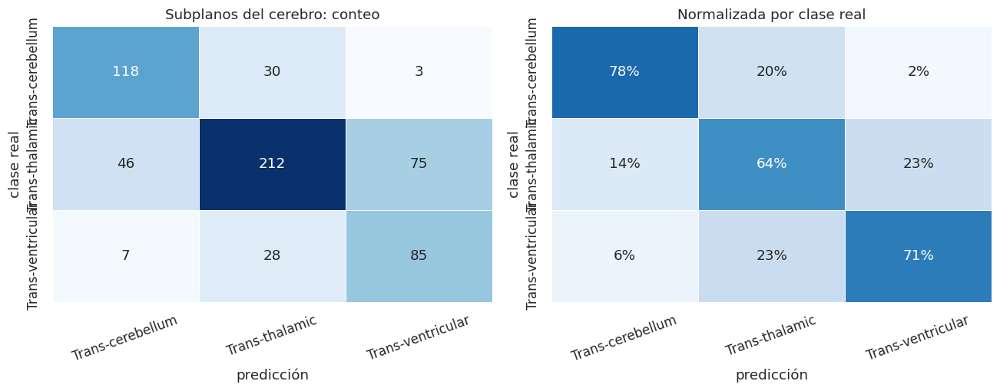

In [ ]:
# 12b. entrenar o cargar el clasificador de subplanos (EfficientNetV2-B0) y evaluarlo
RETRAIN_SUB = False
SUB_EP_HEAD, SUB_EP_FINE = 5, 15        # hay pocas imágenes, se dejan más épocas; el early stopping corta si no mejora

def make_ds_sub(df, training):
    n = len(SUB_CLASES)
    paths  = df['filepath'].astype(str).values
    labels = df['Sub'].map(sub_idx).values.astype('int32')
    def _load(p, l):
        img = tf.io.decode_image(tf.io.read_file(p), channels=3, expand_animations=False)
        img.set_shape([None, None, 3])
        img = tf.cast(tf.clip_by_value(tf.image.resize(img, (IMG_SIZE, IMG_SIZE)), 0, 255), tf.uint8)
        return img, tf.one_hot(l, n)
    ds = tf.data.Dataset.from_tensor_slices((paths, labels)).map(_load, num_parallel_calls=tf.data.AUTOTUNE).cache()
    if training:
        ds = ds.shuffle(1024, seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

sub_tr_ds, sub_va_ds, sub_te_ds = make_ds_sub(cer_fit, True), make_ds_sub(cer_val, False), make_ds_sub(cer_te, False)
_w = class_weight.compute_class_weight('balanced', classes=np.arange(len(SUB_CLASES)), y=cer_fit['Sub'].map(sub_idx).values)
SUB_WEIGHT = {i: float(w) for i, w in enumerate(_w)}
print('Pesos de clase:', {SUB_CLASES[i]: round(w, 2) for i, w in SUB_WEIGHT.items()})

model_sub, info_sub = get_or_train_cnn('EfficientNetV2B0_cerebro', EfficientNetV2B0, 'EfficientNetV2B0_subplanos_v3.keras',
                                       RETRAIN_SUB, ep_head=SUB_EP_HEAD, ep_fine=SUB_EP_FINE,
                                       data=(sub_tr_ds, sub_va_ds, SUB_WEIGHT, len(SUB_CLASES)))
probs_sub = model_sub.predict(sub_te_ds, verbose=0)
y_sub = cer_te['Sub'].map(sub_idx).values
pred_sub = probs_sub.argmax(1)
print(classification_report(y_sub, pred_sub, target_names=SUB_CLASES, digits=3))

cm = confusion_matrix(y_sub, pred_sub)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=SUB_CLASES, yticklabels=SUB_CLASES, ax=ax[0], cbar=False, linewidths=.5)
sns.heatmap(confusion_matrix(y_sub, pred_sub, normalize='true'), annot=True, fmt='.0%', cmap='Blues', vmin=0, vmax=1,
            xticklabels=SUB_CLASES, yticklabels=SUB_CLASES, ax=ax[1], cbar=False, linewidths=.5)
ax[0].set_title('Subplanos del cerebro: conteo'); ax[1].set_title('Normalizada por clase real')
for a_ in ax:
    a_.set_xlabel('predicción'); a_.set_ylabel('clase real'); a_.tick_params(axis='x', rotation=20)
plt.tight_layout(); plt.savefig(FIGS_DIR / 'cm_subplanos_cerebro.png', dpi=150); plt.show()

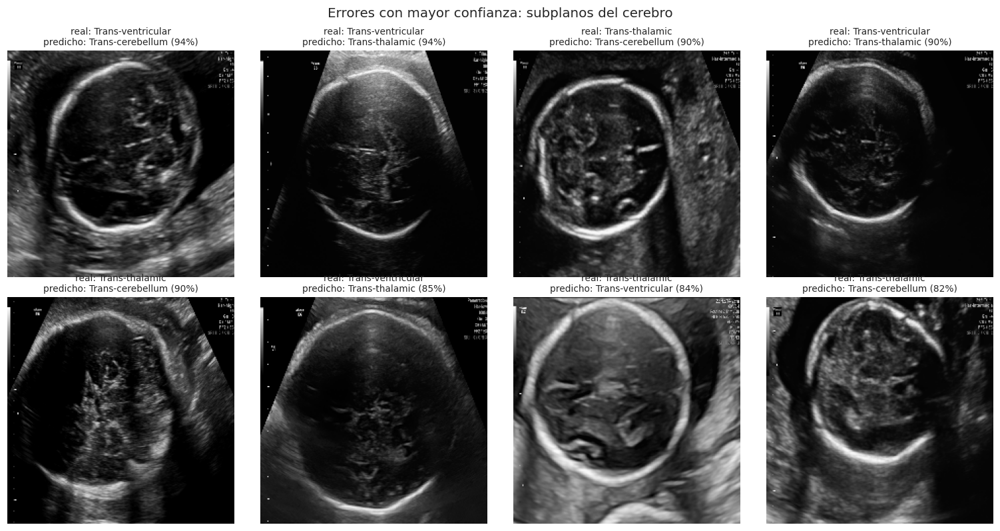

Modelo general usado: ViT-B/16 | imágenes de cerebro que detecta como cerebro: 0.995
Exactitud de subplano sobre cerebros reales (con la etiqueta correcta): 0.687


In [ ]:
# 12c. errores más seguros del clasificador de subplanos y cuánto cambia la exactitud si el modelo general falla antes
err = np.where(pred_sub != y_sub)[0]
err = err[np.argsort(-probs_sub[err, pred_sub[err]])][:8]
if len(err):
    fig, axes = plt.subplots(2, 4, figsize=(14, 7.4))
    for a_, i in zip(axes.ravel(), err):
        a_.imshow(read_rgb(cer_te.iloc[i]['filepath']))
        a_.set_title(f"real: {SUB_CLASES[y_sub[i]]}\npredicho: {SUB_CLASES[pred_sub[i]]} ({probs_sub[i, pred_sub[i]]*100:.0f}%)", fontsize=9)
    for a_ in axes.ravel():
        a_.axis('off')
    plt.suptitle('Errores con mayor confianza: subplanos del cerebro', fontsize=13); plt.tight_layout()
    plt.savefig(FIGS_DIR / 'errores_subplanos.png', dpi=150); plt.show()

# canalización completa: el modelo general decide si es cerebro y, si lo es, el segundo modelo decide el subplano
nombre_ref = max(RESULTS, key=lambda n: RESULTS[n]['rep']['macro avg']['f1-score'])
brain_idx = class_to_idx['Fetal brain']
es_cerebro = RESULTS[nombre_ref]['pred'] == brain_idx
print(f'Modelo general usado: {nombre_ref} | imágenes de cerebro que detecta como cerebro: {es_cerebro[true_labels == brain_idx].mean():.3f}')
print(f'Exactitud de subplano sobre cerebros reales (con la etiqueta correcta): {(pred_sub == y_sub).mean():.3f}')

## 13. Robustez y repetición de los resultados

Esta sección responde dos preguntas que la tabla comparativa no contesta sola (la prueba de McNemar y los intervalos de confianza ya están en la celda 10h):
1. **¿Los modelos funcionan igual con todos los equipos de ultrasonido y operadores?** La celda 13a usa las predicciones que ya existen y corre en segundos. La 13c es un experimento que deja un equipo completo fuera del entrenamiento.
2. **¿Los resultados se repiten con otros splits?** La celda 13b hace validación cruzada por paciente de 5 folds con los tres modelos y reporta media y desviación, y la diferencia entre modelos fold a fold.

Las celdas 13b y 13c entrenan modelos y están apagadas por defecto (`RUN_CV`, `RUN_LOMO`). Guardan lo que van terminando en Drive, así que se pueden reanudar si Colab se corta.

Imágenes originales por equipo: {'Voluson E6': 5012, 'Aloka': 4533, 'Voluson S10': 971, 'Other': 327}
Imágenes de test por equipo   : {'Aloka': 1012, 'Voluson E6': 978, 'Voluson S10': 229, 'Other': 72}
Imágenes originales por equipo y clase (si una clase casi no aparece en un equipo, equipo y clase están mezclados):


Plane,Fetal abdomen,Fetal brain,Fetal femur,Fetal thorax,Maternal cervix,Other
US_Machine,,,,,,
Aloka,209,624,290,276,603,2531
Other,35,127,48,29,85,3
Voluson E6,357,1968,594,1277,705,111
Voluson S10,98,261,74,74,33,431


,imágenes,pacientes,EfficientNetV2-B0 acc,EfficientNetV2-B0 F1,DenseNet-121 acc,DenseNet-121 F1,ViT-B/16 acc,ViT-B/16 F1
equipo,,,,,,,,
Aloka,1012,166,0.958,0.938,0.957,0.930,0.960,0.942
Other,72,24,0.972,0.953,0.972,0.948,0.986,0.970
Voluson E6,978,154,0.970,0.918,0.973,0.930,0.983,0.956
Voluson S10,229,21,0.952,0.944,0.926,0.913,0.939,0.931


,imágenes,pacientes,EfficientNetV2-B0 acc,EfficientNetV2-B0 F1,DenseNet-121 acc,DenseNet-121 F1,ViT-B/16 acc,ViT-B/16 F1
operador,,,,,,,,
Op. 1,451,77,0.958,0.894,0.958,0.902,0.971,0.939
Op. 2,408,60,0.983,0.956,0.988,0.965,0.993,0.980
Op. 3,744,64,0.942,0.933,0.941,0.925,0.946,0.937
Other,688,170,0.977,0.963,0.969,0.952,0.977,0.964


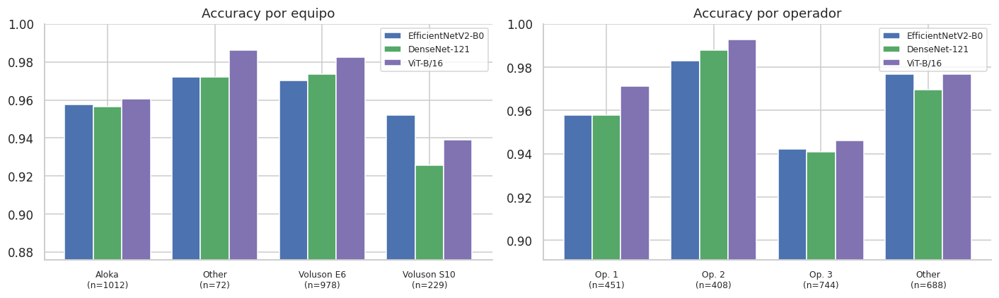

Ojo: equipo y operador están muy relacionados (cada operador usa pocos equipos) y las clases no están igual de repartidas en cada grupo; una diferencia entre grupos no prueba por sí sola que el modelo dependa del equipo. Para eso está el experimento de la celda 13c.


In [ ]:
# 13a. rendimiento por equipo de ultrasonido y por operador (con las predicciones ya hechas, no entrena nada)
from sklearn.metrics import f1_score

def cargar_metadatos():
    for p in [DATASET_DIR / 'FETAL_PLANES_DB_data.csv', DATASET_DIR.parent / 'FETAL_PLANES_DB_data.csv']:
        if p.exists():
            d = pd.read_csv(p, sep=';')
            if d.shape[1] == 1:
                d = pd.read_csv(p, sep=',')
            d['stem'] = d['Image_name'].astype(str).map(lambda x: Path(x).stem)
            return d.drop_duplicates('stem').set_index('stem')[['US_Machine', 'Operator']]
    raise FileNotFoundError('No se encontró FETAL_PLANES_DB_data.csv: copiarlo a la carpeta dataset')

meta_us = cargar_metadatos()
df_orig = pd.concat([orig_tr, df_test], ignore_index=True)       # todas las imágenes originales, con su filepath, paciente y split
for d in (df_orig, df_test):
    for col in ('US_Machine', 'Operator'):
        d[col] = d['fname'].map(lambda x: meta_us[col].get(Path(x).stem))
print('Imágenes originales por equipo:', df_orig['US_Machine'].value_counts().to_dict())
print('Imágenes de test por equipo   :', df_test['US_Machine'].value_counts().to_dict())
print('Imágenes originales por equipo y clase (si una clase casi no aparece en un equipo, equipo y clase están mezclados):')
display(pd.crosstab(df_orig['US_Machine'], df_orig['Plane']))

nombres = list(RESULTS)
MIN_N = 30                  # grupos con menos imágenes de test no se reportan: la cifra no sería confiable
todas = []
for col, tit in (('US_Machine', 'equipo'), ('Operator', 'operador')):
    filas = []
    for g, sub in df_test.groupby(col):
        if len(sub) < MIN_N:
            continue
        ix = sub.index.values; y = true_labels[ix]
        fila = {tit: g, 'imágenes': len(ix), 'pacientes': sub['patient'].nunique()}
        for n in nombres:
            p = RESULTS[n]['pred'][ix]
            fila[f'{n} acc'] = (p == y).mean()
            fila[f'{n} F1'] = f1_score(y, p, average='macro', labels=np.unique(y), zero_division=0)
        filas.append(fila)
    t = pd.DataFrame(filas).set_index(tit)
    display(t.style.format({c: '{:.3f}' for c in t.columns if c.endswith(('acc', 'F1'))}))
    t.to_csv(DATASET_DIR / f'robustez_por_{tit}_v3.csv')
    todas.append((tit, t))

fig, ax = plt.subplots(1, len(todas), figsize=(6.5 * len(todas), 4), squeeze=False)
for a_, (tit, t) in zip(ax[0], todas):
    w = 0.8 / len(nombres); x = np.arange(len(t))
    for k, n in enumerate(nombres):
        a_.bar(x + k * w, t[f'{n} acc'], w, color=COLORES[n], label=n)
    a_.set_xticks(x + w * (len(nombres) - 1) / 2); a_.set_xticklabels([f'{i}\n(n={t.loc[i, "imágenes"]})' for i in t.index], fontsize=8)
    a_.set_ylim(max(0.5, t[[f'{n} acc' for n in nombres]].values.min() - 0.05), 1.0); a_.set_title(f'Accuracy por {tit}'); a_.legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIGS_DIR / 'robustez_equipo_operador.png', dpi=150); plt.show()
print('Ojo: equipo y operador están muy relacionados (cada operador usa pocos equipos) y las clases no están igual de repartidas en cada grupo; una diferencia entre grupos no prueba por sí sola que el modelo dependa del equipo. Para eso está el experimento de la celda 13c.')

In [ ]:
# 13b. validación cruzada por paciente (5 folds) con los tres modelos, y diferencias entre modelos fold a fold
# Solo usa imágenes originales (las aumentadas no entran, así que no hay fuga de copias entre folds). En cada fold los pacientes
# del test no aparecen en el entrenamiento ni en la validación interna. Cada resultado se guarda al terminar, así se puede reanudar.
import gc, tempfile
from scipy import stats

def pesos_clase(y):
    # pesos "balanced" sobre las clases que hay en y; una clase ausente (puede pasar al dejar un equipo fuera) queda con peso 1
    presentes = np.unique(y)
    w = class_weight.compute_class_weight('balanced', classes=presentes, y=y)
    cw = {i: 1.0 for i in range(num_classes)}
    cw.update({int(c): float(v) for c, v in zip(presentes, w)})
    return cw

def entrenar_rapido(base_fn, tag, tr_df_, va_df_, preprocess=None, ep_head=3, ep_fine=6, seed=SEED):
    # mismo esquema de dos fases que el entrenamiento principal, con menos épocas; devuelve el modelo con los mejores pesos de validación
    tf.random.set_seed(seed); np.random.seed(seed)
    cw = pesos_clase(tr_df_['Plane'].map(class_to_idx).values)
    tr, va = make_ds(tr_df_, True), make_ds(va_df_, False)
    tmp = tempfile.gettempdir()
    model, base = build_cnn(base_fn, tag, preprocess)
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss='categorical_crossentropy', metrics=['accuracy'])
    model.fit(tr, validation_data=va, epochs=ep_head, class_weight=cw, callbacks=_callbacks(2, f'{tmp}/{tag}_h.weights.h5'), verbose=2)
    base.trainable = True
    for layer in base.layers:
        if isinstance(layer, tf.keras.layers.BatchNormalization):
            layer.trainable = False
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-5), loss='categorical_crossentropy', metrics=['accuracy'])
    model.fit(tr, validation_data=va, epochs=ep_fine, class_weight=cw, callbacks=_callbacks(3, f'{tmp}/{tag}_f.weights.h5'), verbose=2)
    return model

def entrenar_rapido_vit(tr_df_, va_df_, seed=SEED, ep_head=3, ep_fine=5):
    # el ViT de pytorch con el mismo esquema (cabeza y luego todo el modelo); devuelve el modelo ya entrenado
    torch.manual_seed(seed); np.random.seed(seed)
    Xtr_ = load_many(tr_df_['filepath']); ytr_ = tr_df_['Plane'].map(class_to_idx).values.astype('int64')
    Xva_ = load_many(va_df_['filepath']); yva_ = va_df_['Plane'].map(class_to_idx).values.astype('int64')
    cw_d = pesos_clase(ytr_); cw = torch.tensor([cw_d[i] for i in range(num_classes)], dtype=torch.float32, device=device)
    m = ViTClassifier(num_classes).to(device)
    for p_ in m.vit.parameters():
        p_.requires_grad = False
    run_phase(m, m.head.parameters(), LR_HEAD_VIT, ep_head, Xtr_, ytr_, Xva_, yva_, cw, BS_VIT, 2, 'cabeza')
    for p_ in m.vit.parameters():
        p_.requires_grad = True
    run_phase(m, m.parameters(), LR_FINE_VIT, ep_fine, Xtr_, ytr_, Xva_, yva_, cw, BS_VIT, 3, 'fine-tuning')
    return m

def validacion_interna(tr_df_, seed):
    # separa ~1/8 de los pacientes del entrenamiento para validar; ningún paciente queda en los dos lados
    ia, ib = next(StratifiedGroupKFold(8, shuffle=True, random_state=seed).split(tr_df_, tr_df_['Plane'], groups=tr_df_['patient']))
    fit, val = tr_df_.iloc[ia].reset_index(drop=True), tr_df_.iloc[ib].reset_index(drop=True)
    assert not set(fit['patient']) & set(val['patient'])
    return fit, val

RUN_CV = True                       # True: entrena 5 folds por modelo (unas 1,5 h en una T4 con una semilla; estimado, no medido)
CV_MODELOS = {'EfficientNetV2-B0': ('cnn', EfficientNetV2B0, None),
              'DenseNet-121':      ('cnn', DenseNet121, 'imagenet_torch'),
              'ViT-B/16':          ('vit', None, None)}                 # quitar una línea para correr menos modelos
CV_SEMILLAS = [42]                   # con más semillas, por ejemplo [42, 7, 123], también se mide la variación entre corridas
CV_PATH = DATASET_DIR / 'cv_resultados_v3.json'
cv_res = json.loads(CV_PATH.read_text()) if CV_PATH.exists() else {}

if RUN_CV:
    for seed in CV_SEMILLAS:
        folds = StratifiedGroupKFold(5, shuffle=True, random_state=seed).split(df_orig, df_orig['Plane'], groups=df_orig['patient'])
        for fold, (a, b) in enumerate(folds):
            trf, tef = df_orig.iloc[a], df_orig.iloc[b].reset_index(drop=True)
            assert not set(trf['patient']) & set(tef['patient'])
            fit, val = validacion_interna(trf, seed)
            y = tef['Plane'].map(class_to_idx).values
            for nombre, (tipo, fn, pre) in CV_MODELOS.items():
                clave = f'{nombre}|{seed}|{fold}'
                if clave in cv_res:
                    continue
                print(f'== {clave} | entrenamiento {len(fit)} | validación {len(val)} | test {len(tef)} ==')
                if tipo == 'cnn':
                    model = entrenar_rapido(fn, f'cv_{nombre}', fit, val, pre, seed=seed + fold)
                    p = model.predict(make_ds(tef, False), verbose=0).argmax(1)
                else:
                    model = entrenar_rapido_vit(fit, val, seed=seed + fold)
                    p = predict_probs(model, load_many(tef['filepath'])).argmax(1)
                cv_res[clave] = {'acc': float((p == y).mean()), 'f1': float(f1_score(y, p, average='macro')), 'n_test': int(len(y))}
                CV_PATH.write_text(json.dumps(cv_res, indent=1))       # se guarda al terminar cada fold
                del model; gc.collect()
                if device == 'cuda':
                    torch.cuda.empty_cache()

if cv_res:
    cv_df = pd.DataFrame([{**dict(zip(('Modelo', 'semilla', 'fold'), k.split('|'))), **v} for k, v in cv_res.items()])
    resumen = cv_df.groupby('Modelo').agg(accuracy_media=('acc', 'mean'), accuracy_std=('acc', 'std'), f1_media=('f1', 'mean'), f1_std=('f1', 'std'), corridas=('acc', 'size'))
    display(resumen.style.format({c: '{:.3f}' for c in resumen.columns if c != 'corridas'}))
    resumen.to_csv(DATASET_DIR / 'cv_resumen_v3.csv')

    # diferencias entre modelos en los mismos folds (comparación pareada) con intervalo t del 95 %
    piv = cv_df.pivot_table(index=['semilla', 'fold'], columns='Modelo', values='acc')
    filas = []
    for i, a_ in enumerate(piv.columns):
        for b_ in piv.columns[i + 1:]:
            d = (piv[a_] - piv[b_]).dropna()
            if len(d) >= 3:
                sd = d.std(ddof=1); lo, hi = stats.t.interval(0.95, len(d) - 1, loc=d.mean(), scale=sd / np.sqrt(len(d))) if sd > 0 else (d.mean(), d.mean())
                filas.append({'Comparación': f'{a_} - {b_}', 'folds': len(d), 'diferencia media de accuracy': d.mean(), 'IC 95 %': f'[{lo:+.3f}, {hi:+.3f}]',
                              'el primero gana en': f'{int((d > 0).sum())} de {len(d)} folds'})
    if filas:
        display(pd.DataFrame(filas).set_index('Comparación').style.format({'diferencia media de accuracy': '{:+.3f}'}))
        print('Los folds comparten parte del entrenamiento, así que no son independientes y el intervalo es optimista; sirve como orden de magnitud, no como prueba.')

    fig, ax = plt.subplots(figsize=(6.5, 4))
    for k, (m, g) in enumerate(cv_df.groupby('Modelo')):
        ax.scatter(np.full(len(g), k) + np.random.default_rng(0).uniform(-.08, .08, len(g)), g['acc'], color=COLORES.get(m, 'gray'), s=45)
        ax.hlines(g['acc'].mean(), k - .25, k + .25, color='black')
    ax.set_xticks(range(cv_df['Modelo'].nunique())); ax.set_xticklabels(sorted(cv_df['Modelo'].unique())); ax.set_ylabel('accuracy por fold')
    ax.set_title('Validación cruzada por paciente'); plt.tight_layout(); plt.savefig(FIGS_DIR / 'validacion_cruzada.png', dpi=150); plt.show()
else:
    print('Todavía no hay resultados de validación cruzada: poner RUN_CV = True y ejecutar esta celda.')

== EfficientNetV2-B0|42|0 | entrenamiento 7313 | validación 1239 | test 2291 ==
Epoch 1/3
115/115 - 104s - 907ms/step - accuracy: 0.7593 - loss: 0.6874 - val_accuracy: 0.8797 - val_loss: 0.3664 - learning_rate: 0.0010
Epoch 2/3
115/115 - 13s - 110ms/step - accuracy: 0.8583 - loss: 0.4114 - val_accuracy: 0.8886 - val_loss: 0.3406 - learning_rate: 0.0010
Epoch 3/3
115/115 - 21s - 179ms/step - accuracy: 0.8842 - loss: 0.3361 - val_accuracy: 0.8943 - val_loss: 0.3064 - learning_rate: 0.0010
Restoring model weights from the end of the best epoch: 3.
Epoch 1/6
115/115 - 75s - 656ms/step - accuracy: 0.9056 - loss: 0.2711 - val_accuracy: 0.9290 - val_loss: 0.2321 - learning_rate: 1.0000e-05
Epoch 2/6
115/115 - 30s - 265ms/step - accuracy: 0.9188 - loss: 0.2272 - val_accuracy: 0.9362 - val_loss: 0.2032 - learning_rate: 1.0000e-05
Epoch 3/6
115/115 - 31s - 269ms/step - accuracy: 0.9340 - loss: 0.1869 - val_accuracy: 0.9403 - val_loss: 0.1841 - learning_rate: 1.0000e-05
Epoch 4/6

Epoch 4: Reduce

  0%|          | 0/7313 [00:00<?, ?it/s]

  0%|          | 0/1239 [00:00<?, ?it/s]

[cabeza] época 1/3 | loss 1.1270 | val_loss 0.6796 | val_acc 0.8023
[cabeza] época 2/3 | loss 0.6484 | val_loss 0.4870 | val_acc 0.8475
[cabeza] época 3/3 | loss 0.5043 | val_loss 0.4060 | val_acc 0.8822
[fine-tuning] época 1/5 | loss 0.2662 | val_loss 0.2264 | val_acc 0.9298
[fine-tuning] época 2/5 | loss 0.1421 | val_loss 0.1501 | val_acc 0.9572
[fine-tuning] época 3/5 | loss 0.1053 | val_loss 0.1416 | val_acc 0.9556
[fine-tuning] época 4/5 | loss 0.0858 | val_loss 0.1339 | val_acc 0.9580
[fine-tuning] época 5/5 | loss 0.0719 | val_loss 0.1388 | val_acc 0.9613


  0%|          | 0/2291 [00:00<?, ?it/s]

== EfficientNetV2-B0|42|1 | entrenamiento 7569 | validación 1039 | test 2235 ==
Epoch 1/3
119/119 - 87s - 732ms/step - accuracy: 0.7488 - loss: 0.7033 - val_accuracy: 0.8903 - val_loss: 0.3366 - learning_rate: 0.0010
Epoch 2/3
119/119 - 20s - 171ms/step - accuracy: 0.8592 - loss: 0.4053 - val_accuracy: 0.9095 - val_loss: 0.2760 - learning_rate: 0.0010
Epoch 3/3
119/119 - 13s - 110ms/step - accuracy: 0.8798 - loss: 0.3375 - val_accuracy: 0.8989 - val_loss: 0.2723 - learning_rate: 0.0010
Restoring model weights from the end of the best epoch: 3.
Epoch 1/6
119/119 - 67s - 566ms/step - accuracy: 0.9051 - loss: 0.2576 - val_accuracy: 0.9365 - val_loss: 0.1822 - learning_rate: 1.0000e-05
Epoch 2/6
119/119 - 35s - 293ms/step - accuracy: 0.9226 - loss: 0.2126 - val_accuracy: 0.9528 - val_loss: 0.1522 - learning_rate: 1.0000e-05
Epoch 3/6
119/119 - 34s - 287ms/step - accuracy: 0.9321 - loss: 0.1838 - val_accuracy: 0.9567 - val_loss: 0.1376 - learning_rate: 1.0000e-05
Epoch 4/6
119/119 - 35s - 2

  0%|          | 0/7569 [00:00<?, ?it/s]

  0%|          | 0/1039 [00:00<?, ?it/s]

[cabeza] época 1/3 | loss 1.1283 | val_loss 0.7836 | val_acc 0.7815
[cabeza] época 2/3 | loss 0.6110 | val_loss 0.5018 | val_acc 0.8556
[cabeza] época 3/3 | loss 0.4857 | val_loss 0.4030 | val_acc 0.8864
[fine-tuning] época 1/5 | loss 0.2427 | val_loss 0.1777 | val_acc 0.9480
[fine-tuning] época 2/5 | loss 0.1251 | val_loss 0.1414 | val_acc 0.9519
[fine-tuning] época 3/5 | loss 0.0933 | val_loss 0.1181 | val_acc 0.9673
[fine-tuning] época 4/5 | loss 0.0780 | val_loss 0.1168 | val_acc 0.9644
[fine-tuning] época 5/5 | loss 0.0597 | val_loss 0.0956 | val_acc 0.9769


  0%|          | 0/2235 [00:00<?, ?it/s]

== EfficientNetV2-B0|42|2 | entrenamiento 7828 | validación 993 | test 2022 ==
Epoch 1/3


In [ ]:
# 13c. dejar un equipo de ultrasonido fuera del entrenamiento (EfficientNetV2-B0) y compararlo con el resultado normal
RUN_LOMO = False                     # True: entrena un modelo por equipo (unos 10 min cada uno con una T4; estimado, no medido)
MIN_IMG_EQUIPO = 300                 # solo equipos con suficientes imágenes para que el resultado signifique algo
LOMO_PATH = DATASET_DIR / 'lomo_resultados_v3.json'
lomo = json.loads(LOMO_PATH.read_text()) if LOMO_PATH.exists() else {}
equipos = df_orig['US_Machine'].value_counts()
equipos = equipos[equipos >= MIN_IMG_EQUIPO].index.tolist()
print('Equipos con >=', MIN_IMG_EQUIPO, 'imágenes:', equipos)

if RUN_LOMO:
    for m in equipos:
        if m in lomo:
            continue
        test_m = df_orig[df_orig['US_Machine'] == m].reset_index(drop=True)
        resto = df_orig[(df_orig['US_Machine'] != m) & ~df_orig['patient'].isin(test_m['patient'])]
        fit, val = validacion_interna(resto, SEED)
        print(f'== equipo fuera: {m} | entrenamiento {len(fit)} | test {len(test_m)} ==')
        model = entrenar_rapido(EfficientNetV2B0, 'lomo', fit, val)
        y = test_m['Plane'].map(class_to_idx).values
        p = model.predict(make_ds(test_m, False), verbose=0).argmax(1)
        lomo[m] = {'acc': float((p == y).mean()), 'f1': float(f1_score(y, p, average='macro', labels=np.unique(y), zero_division=0)), 'n': int(len(y))}
        LOMO_PATH.write_text(json.dumps(lomo, indent=1))
        del model; gc.collect()

if lomo:
    # comparación: el modelo principal, que sí vio ese equipo en el entrenamiento, evaluado en las imágenes de test de ese equipo
    filas = []
    for m, r in lomo.items():
        sub = df_test[df_test['US_Machine'] == m]
        if len(sub) < MIN_N:
            continue
        ix = sub.index.values
        filas.append({'Equipo': m, 'accuracy sin ver el equipo': r['acc'], 'F1 sin ver el equipo': r['f1'],
                      'accuracy modelo principal (vio el equipo)': (RESULTS['EfficientNetV2-B0']['pred'][ix] == true_labels[ix]).mean()})
    lomo_df = pd.DataFrame(filas).set_index('Equipo')
    lomo_df['caída'] = lomo_df['accuracy modelo principal (vio el equipo)'] - lomo_df['accuracy sin ver el equipo']
    display(lomo_df.style.format('{:.3f}'))
    lomo_df.to_csv(DATASET_DIR / 'lomo_comparacion_v3.csv')
    print('Los dos números no son del todo comparables: el modelo "sin ver el equipo" se evalúa en todas las imágenes del equipo y se entrena con menos épocas y menos datos; la columna caída es un orden de magnitud.')
else:
    print('Todavía no hay resultados: poner RUN_LOMO = True y ejecutar esta celda.')

Equipos con >= 300 imágenes: ['Voluson E6', 'Aloka', 'Voluson S10', 'Other']
Todavía no hay resultados: poner RUN_LOMO = True y ejecutar esta celda.
